# Feature sweep — one column at a time

Goal: walk through **every column** of the challenge files, one per section. For each: what it
actually is in plain words, order statistics, and a picture of its distribution — over the 2025
training data and, where meaningful, side by side with the Jan/Jul 2026 `ranking.parquet`.

Data comes from the parquet mirror in `../data/` (see `README.md`). Sections get appended as we go.

**Roadmap** (column order of the files) —
`MVT_ID_mvt` ✅ · `FLIGHT_ID_mvt` ✅ · `FLIGHT_mvt` ✅ · `FLIGHT_RULE_mvt` ✅ · `ADEP_mvt` ✅ · `ADES_mvt` ✅ ·
`PHASE_mvt` ✅ · `MVT_TIME_UTC_mvt` · `BLOCK_TIME_UTC_mvt` · `SCHED_TIME_UTC_mvt` ·
`AIRCRAFT_TYPE_mvt` · `RUNWAY_mvt` · `STAND_mvt` · `TAXITIME_SEC_mvt` (target) · `LOBT_flt` ·
`CALLSIGN_flt` · `ADEP_flt` · `ADES_flt` · `ADES_FILED_flt` · `MARKET_SEGMENT_flt` · `IOBT_flt` ·
`FLIGHT_RULE_flt` · `FLIGHT_TYPE_flt` · `AIRCRAFT_TYPE_flt` · `WK_TBL_CAT_flt` ·
`AIRCRAFT_OPERATOR_flt` · `EOBT_1_flt` · `ARVT_1_flt` · `AOBT_3_flt` · `ARVT_3_flt`

In [1]:
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "eda" else Path.cwd()
con = duckdb.connect()
con.sql("SET TimeZone='UTC'")

# relations: full files; filter PHASE_mvt yourself where it matters
T = f"read_parquet('{ROOT}/data/training_2025-*.parquet')"
R = f"read_parquet('{ROOT}/data/ranking.parquet')"

# chart chrome (dataviz reference palette, light mode)
SURFACE, INK, INK2 = "#fcfcfb", "#0b0b0b", "#52514e"
MUTED, GRID, BASELINE = "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # series: blue = training, orange = ranking
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "sans-serif", "text.color": INK,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelsize": 9.5, "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "xtick.labelsize": 9, "ytick.labelsize": 9,
    "legend.frameon": False, "legend.fontsize": 9.5, "figure.dpi": 110,
})


def style(ax, *, x_grid=False, y_grid=True):
    ax.grid(axis="x", visible=x_grid)
    ax.grid(axis="y", visible=y_grid)
    ax.tick_params(length=0)


def order_stats(expr, where="TRUE"):
    """Order statistics of a numeric expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   count(DISTINCT ({expr})) n_unique,
                   min({expr}) min,
                   quantile_cont({expr}, 0.01) p01,
                   quantile_cont({expr}, 0.25) p25,
                   quantile_cont({expr}, 0.50) p50,
                   quantile_cont({expr}, 0.75) p75,
                   quantile_cont({expr}, 0.99) p99,
                   max({expr}) max
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")


def cat_stats(expr, where="TRUE"):
    """Counts overview of a categorical/string expression, training vs ranking."""
    out = []
    for name, src in [("training 2025", T), ("ranking 2026", R)]:
        out.append(con.sql(f"""
            SELECT '{name}' AS "set", count(*) n,
                   count(*) FILTER (({expr}) IS NULL) n_null,
                   round(100.0*count(*) FILTER (({expr}) IS NULL)/count(*), 2) pct_null,
                   count(DISTINCT ({expr})) n_unique
            FROM {src} WHERE {where}""").df())
    return pd.concat(out, ignore_index=True).set_index("set")

## 1 · `MVT_ID_mvt` — the movement record's serial number

Every row in these files is one **movement**: one aircraft either departing from or arriving at
one of the 10 challenge airports. `MVT_ID_mvt` is simply the unique number the data pipeline
stamped on that record — a ticket number, nothing more. It is stored as a `double` but always
holds a whole number.

It matters for exactly one reason: it is the **join key**. `submitting.parquet` lists the
344,841 IDs (the ranking file's departures) we must attach a prediction to, and the scorer
matches our rows back by this value.

Worth checking anyway: are IDs handed out in time order, and do the training and ranking ranges
overlap?

In [2]:
order_stats("MVT_ID_mvt").style.format("{:,.0f}")

,n,n_null,n_unique,min,p01,p25,p50,p75,p99,max
set,,,,,,,,,,
training 2025,"4,167,797",0,"4,167,797","181,979,889","182,025,388","186,141,700","191,629,277","196,798,593","201,988,182","202,064,541"
ranking 2026,"689,534",0,"689,534","202,180,234","202,187,336","202,714,448","212,267,996","213,152,543","213,820,148","213,827,173"


In [3]:
non_int = con.sql(f"SELECT count(*) FROM {T} WHERE MVT_ID_mvt != floor(MVT_ID_mvt)").fetchone()[0]
overlap = con.sql(f"""SELECT count(*) FROM (SELECT MVT_ID_mvt FROM {T}) t
                      JOIN (SELECT MVT_ID_mvt FROM {R}) r USING (MVT_ID_mvt)""").fetchone()[0]
sub_match = con.sql(f"""
    SELECT count(*) = 0 FROM (
        SELECT MVT_ID_mvt FROM read_parquet('{ROOT}/data/submitting.parquet')
        FULL JOIN (SELECT MVT_ID_mvt AS id2, 1 one FROM {R} WHERE PHASE_mvt = 'DEP') r
            ON MVT_ID_mvt = id2
        WHERE MVT_ID_mvt IS NULL OR id2 IS NULL)""").fetchone()[0]
rank_corr = con.sql(f"""
    SELECT round(corr(rank_id, rank_t), 4) FROM (
        SELECT rank() OVER (ORDER BY MVT_ID_mvt) rank_id,
               rank() OVER (ORDER BY MVT_TIME_UTC_mvt) rank_t
        FROM (SELECT * FROM {T} USING SAMPLE reservoir(100000) REPEATABLE (42)))""").fetchone()[0]

print(f"non-integer values in training:            {non_int}")
print(f"IDs shared between training and ranking:   {overlap}")
print(f"submitting.parquet IDs == ranking DEP IDs: {sub_match}")
print(f"rank corr(MVT_ID, movement time), 100k:    {rank_corr}")

non-integer values in training:            0
IDs shared between training and ranking:   0
submitting.parquet IDs == ranking DEP IDs: True
rank corr(MVT_ID, movement time), 100k:    0.9927


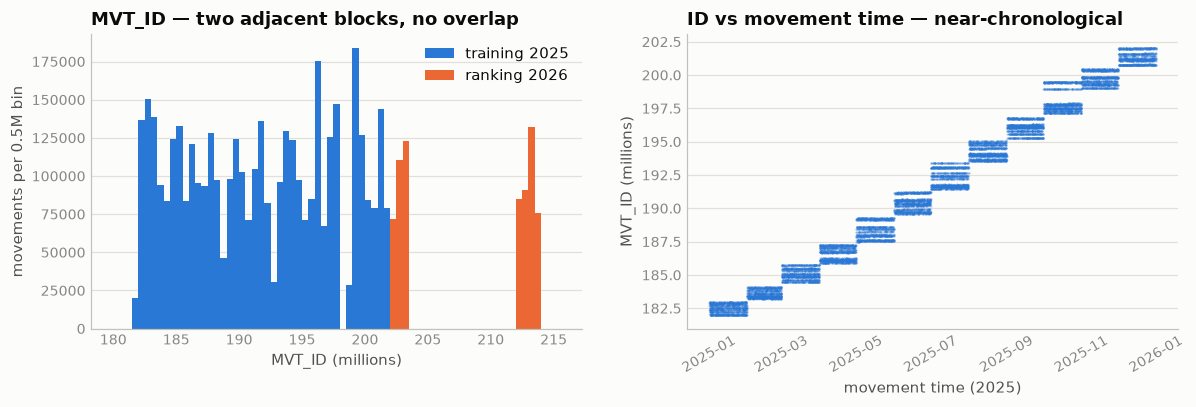

In [4]:
ids_t = con.sql(f"SELECT MVT_ID_mvt/1e6 v FROM {T}").df().v
ids_r = con.sql(f"SELECT MVT_ID_mvt/1e6 v FROM {R}").df().v
samp = con.sql(f"""SELECT MVT_TIME_UTC_mvt t, MVT_ID_mvt/1e6 v FROM {T}
                   USING SAMPLE reservoir(20000) REPEATABLE (42)""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.arange(180, 216, 0.5)
a1.hist(ids_t, bins=bins, color=BLUE, label="training 2025")
a1.hist(ids_r, bins=bins, color=ORANGE, label="ranking 2026")
a1.set_title("MVT_ID — two adjacent blocks, no overlap")
a1.set_xlabel("MVT_ID (millions)")
a1.set_ylabel("movements per 0.5M bin")
a1.legend()
style(a1)

a2.scatter(samp.t, samp.v, s=2, color=BLUE, alpha=0.25, linewidths=0)
a2.set_title("ID vs movement time — near-chronological")
a2.set_xlabel("movement time (2025)")
a2.set_ylabel("MVT_ID (millions)")
a2.tick_params(axis="x", rotation=30)
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- All values are unique whole numbers, never null — in both files. Treat as an `int64` key.
- Ranking IDs (202.2M–213.8M) sit **entirely above** training's (182.0M–202.1M); zero overlap,
  and `submitting.parquet` is exactly the ranking departures' ID set. Within ranking, Jan and
  Jul 2026 form two separate ID blocks (~202–204M and ~212–214M) — IDs kept ticking through the
  months we don't see.
- IDs are handed out in near time order (rank corr ≈ 0.99 with movement time), in monthly
  batches — the scatter shows a staircase, with adjacent months' ID ranges overlapping. A few
  early-2025 rows carry IDs from ranges otherwise belonging to late 2025 (January's max ID is
  ≈ 202.06M, close to December's) — records reprocessed long after the fact.
- **Use in modeling: none** — it's a join key. Any signal it carries is record-creation time,
  which we get directly and more honestly from the timestamp columns.

## 2 · `FLIGHT_ID_mvt` — the matched flight plan's serial number

Two different systems feed these files. Airports record **movements** (a plane pushed back, a
plane took off); EUROCONTROL's Network Manager (NM) records **flight plans**. This column holds
the ID of the NM flight that the movement was matched to — *when* that match succeeded. All the
`*_flt` columns to the right come along with this match.

One NM flight = one leg (say, Heathrow → CDG). So when **both** ends of a leg are challenge
airports, the same `FLIGHT_ID` legitimately appears on two rows: once as `DEP` at the origin,
once as `ARR` at the destination.

Things to check: how often is it missing (and is missing-ness structured?), the duplicate
pattern, and whether the training/ranking ID ranges are disjoint like `MVT_ID`'s were.

In [5]:
order_stats("FLIGHT_ID_mvt").style.format("{:,.0f}")

,n,n_null,n_unique,min,p01,p25,p50,p75,p99,max
set,,,,,,,,,,
training 2025,"4,167,797","30,930","3,821,595","280,340,526","280,498,586","283,937,522","287,175,586","291,184,686","294,420,395","294,567,590"
ranking 2026,"689,534","6,692","631,919","294,555,620","294,595,907","295,178,090","301,566,458","302,233,972","302,935,620","302,958,437"


In [6]:
# structure of the non-null values
dup = con.sql(f"""
    SELECT cnt, count(*) n_ids FROM (
        SELECT FLIGHT_ID_mvt, count(*) cnt FROM {T}
        WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1)
    GROUP BY 1 ORDER BY 1""").df()
combos = con.sql(f"""
    SELECT phases, count(*) n_ids FROM (
        SELECT FLIGHT_ID_mvt, string_agg(PHASE_mvt, '+' ORDER BY PHASE_mvt) phases
        FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 HAVING count(*) = 2)
    GROUP BY 1 ORDER BY n_ids DESC""").df()
ades_ok, pairs = con.sql(f"""
    SELECT sum((d_ades = a_airport)::INT), count(*) FROM (
        SELECT max(CASE WHEN PHASE_mvt='DEP' THEN ADES_mvt END) d_ades,
               max(CASE WHEN PHASE_mvt='ARR' THEN ADES_mvt END) a_airport
        FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL
        GROUP BY FLIGHT_ID_mvt HAVING count(*) = 2 AND count(DISTINCT PHASE_mvt) = 2)""").fetchone()
xtab = con.sql(f"""
    SELECT FLIGHT_ID_mvt IS NULL id_null, CALLSIGN_flt IS NULL flt_block_null, count(*) n
    FROM {T} GROUP BY 1, 2 ORDER BY n DESC""").df()
vfr = con.sql(f"""
    SELECT count(*), count(*) FILTER (FLIGHT_ID_mvt IS NULL)
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V'""").fetchone()
shared = con.sql(f"""
    SELECT count(DISTINCT t.FLIGHT_ID_mvt)
    FROM {T} t JOIN {R} r ON t.FLIGHT_ID_mvt = r.FLIGHT_ID_mvt""").fetchone()[0]

print("appearances per non-null ID (training):")
print(dup.to_string(index=False))
print("\nphase combos of the twice-appearing IDs:")
print(combos.to_string(index=False))
print(f"\nDEP+ARR pairs where DEP's destination == ARR's airport: {ades_ok:,.0f} of {pairs:,} (same leg, both ends)")
print("\nFLIGHT_ID null vs whole _flt block null:")
print(xtab.to_string(index=False))
print(f"\nVFR departures: {vfr[0]:,} — unmatched: {vfr[1]:,} (all of them)")
print(f"FLIGHT_IDs appearing in BOTH training and ranking: {shared}")

appearances per non-null ID (training):
 cnt   n_ids
   1 3506323
   2  315272

phase combos of the twice-appearing IDs:
 phases  n_ids
ARR+DEP 315269
DEP+DEP      3

DEP+ARR pairs where DEP's destination == ARR's airport: 313,639 of 315,269 (same leg, both ends)

FLIGHT_ID null vs whole _flt block null:
 id_null  flt_block_null       n
   False           False 4129878
    True            True   30930
   False            True    6989

VFR departures: 2,930 — unmatched: 2,930 (all of them)
FLIGHT_IDs appearing in BOTH training and ranking: 4


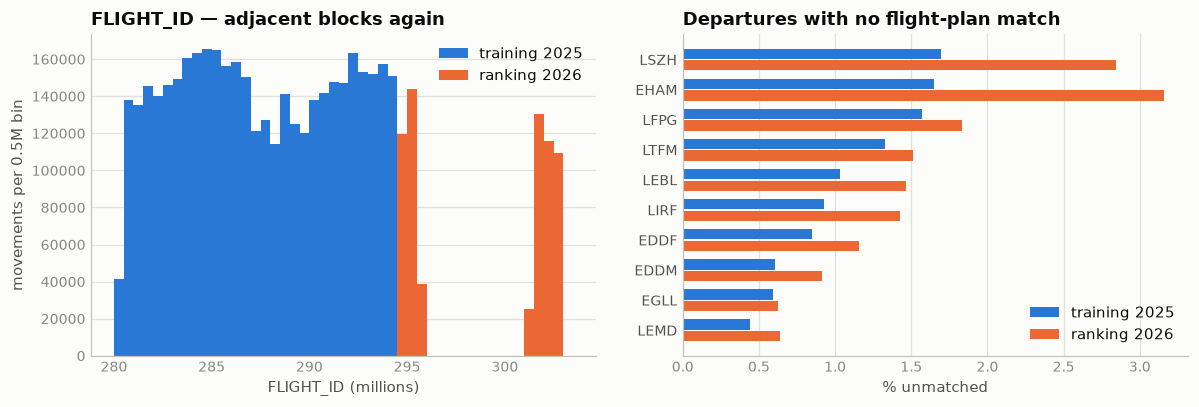

In [7]:
ids_t = con.sql(f"SELECT FLIGHT_ID_mvt/1e6 v FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL").df().v
ids_r = con.sql(f"SELECT FLIGHT_ID_mvt/1e6 v FROM {R} WHERE FLIGHT_ID_mvt IS NOT NULL").df().v
unm = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {T} WHERE PHASE_mvt='DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt a, 100.0*count(*) FILTER (FLIGHT_ID_mvt IS NULL)/count(*) pct
               FROM {R} WHERE PHASE_mvt='DEP' GROUP BY 1)
    SELECT t.a airport, t.pct pct_t, r.pct pct_r FROM t JOIN r ON t.a = r.a ORDER BY t.pct""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.arange(280, 304, 0.5)
a1.hist(ids_t, bins=bins, color=BLUE, label="training 2025")
a1.hist(ids_r, bins=bins, color=ORANGE, label="ranking 2026")
a1.set_title("FLIGHT_ID — adjacent blocks again")
a1.set_xlabel("FLIGHT_ID (millions)")
a1.set_ylabel("movements per 0.5M bin")
a1.legend()
style(a1)

y = np.arange(len(unm))
a2.barh(y + 0.19, unm.pct_t, height=0.34, color=BLUE, label="training 2025")
a2.barh(y - 0.19, unm.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a2.set_yticks(y, unm.airport, color=INK2)
a2.set_title("Departures with no flight-plan match")
a2.set_xlabel("% unmatched")
a2.legend(loc="lower right")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- Missing on 0.74% of training rows (DEP 1.08%, ARR 0.41%) and 0.97% of ranking rows (DEP
  1.53%) — when it's missing, the *entire* `_flt` block is empty. The reverse doesn't quite
  hold: 6,989 rows (almost all arrivals) carry a `FLIGHT_ID` yet still have an empty `_flt`
  block — matched, but the plan data didn't come through.
- **All 2,930 VFR departures are unmatched** — VFR flights don't file NM flight plans. Beyond
  those, unmatched share is highest at Zurich and Schiphol and peaks in summer (general-aviation
  season): missing-ness is *structured*, not random.
- 315,272 IDs appear on exactly two rows; 315,269 of those are a `DEP`+`ARR` pair, and for
  99.5% the departure's destination equals the arrival's airport — the **same leg seen from both
  challenge airports** (the rest are diversions/inconsistencies; 3 odd `DEP`+`DEP` cases).
- Ranking's ID block again sits above training's, but this time they touch: **4 IDs appear in
  both files** — overnight New Year's flights that departed Dec 31, 2025 (training) and landed
  Jan 1, 2026 (ranking). Confirms the files were split by movement date, not by flight.
- Unmatched IFR departures taxi slightly *longer* than matched ones (median 1,009 s vs 911 s);
  unmatched VFR ones much shorter (232 s).
- **Use in modeling:** the value itself is a join key (no signal beyond time). But (a) the
  **is-missing indicator** is a genuine feature — it flags VFR/GA traffic and rows where the
  `AOBT_3`-implied taxi feature won't exist; and (b) the DEP+ARR pairing may help engineered
  features later (linking a leg's two ends). Ranking's higher unmatched rate (1.53%) means the
  no-flight-plan fallback path matters slightly more at prediction time.

### 2a · Addendum — who are the unmatched IFR flights?

Missing VFR matches are *expected* — VFR flights don't file NM flight plans. But an IFR flight
should always have one, and IFR turns out to be the bulk of the unmatched rows:

| flight rule | DEP | ARR | total | missing plan expected? |
|---|---:|---:|---:|---|
| IFR (`I`) | 19,454 | 5,294 | **24,748** | **no — worth investigating** |
| VFR (`V`) | 2,930 | 3,149 | 6,079 | yes |
| unknown | 40 | 63 | 103 | — |

The cell below profiles those 24,748 IFR rows: which airports, which destinations, when, and
whether the same pattern shows up in the ranking data.

In [8]:
U = f"{T} WHERE FLIGHT_ID_mvt IS NULL AND FLIGHT_RULE_mvt = 'I'"

xtab = con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '?') AS flight_rule,
           count(*) FILTER (PHASE_mvt = 'DEP') dep,
           count(*) FILTER (PHASE_mvt = 'ARR') arr, count(*) total
    FROM {T} WHERE FLIGHT_ID_mvt IS NULL GROUP BY 1 ORDER BY total DESC""").df()
by_ap = con.sql(f"""
    SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END airport, count(*) n,
           round(100.0*count(*)/sum(count(*)) OVER (), 1) pct
    FROM {U} GROUP BY 1 ORDER BY n DESC LIMIT 5""").df()
other_end = con.sql(f"""
    SELECT coalesce(CASE WHEN PHASE_mvt = 'DEP' THEN ADES_mvt ELSE ADEP_mvt END, '?') other_end,
           count(*) n
    FROM {U} GROUP BY 1 ORDER BY n DESC LIMIT 8""").df()
by_month = con.sql(f"""
    SELECT month(MVT_TIME_UTC_mvt) m, count(*) n FROM {U} GROUP BY 1 ORDER BY 1""").df()
complete = con.sql(f"""
    SELECT count(*) n, count(*) FILTER (SCHED_TIME_UTC_mvt IS NULL) sched_null,
           count(*) FILTER (RUNWAY_mvt IS NULL) rwy_null,
           count(*) FILTER (STAND_mvt IS NULL) stand_null,
           count(*) FILTER (AIRCRAFT_TYPE_mvt IS NULL) actype_null,
           count(*) FILTER (regexp_matches(FLIGHT_mvt, '^[A-Z]{{3}}[0-9]')) icao_callsign
    FROM {U}""").df()
rk = con.sql(f"""
    SELECT count(*) FILTER (FLIGHT_RULE_mvt = 'I') ifr_unmatched,
           count(*) FILTER (FLIGHT_RULE_mvt = 'I'
               AND CASE WHEN PHASE_mvt='DEP' THEN ADES_mvt ELSE ADEP_mvt END = 'LCEN') ifr_ercan,
           count(*) FILTER (PHASE_mvt = 'DEP' AND ADES_mvt = 'LCEN') dep_to_ercan
    FROM {R} WHERE FLIGHT_ID_mvt IS NULL""").df()

print("unmatched rows by flight rule (training):")
print(xtab.to_string(index=False))
print("\nunmatched IFR — top challenge airports:")
print(by_ap.to_string(index=False))
print("\nunmatched IFR — the leg's other end (note LCEN = Ercan, Northern Cyprus):")
print(other_end.to_string(index=False))
print("\nunmatched IFR — by month:")
print(by_month.set_index("m").T.to_string())
print("\nunmatched IFR — completeness of the movement half:")
print(complete.to_string(index=False))
print("\nranking file: unmatched IFR rows:", rk.ifr_unmatched[0],
      "| involving Ercan:", rk.ifr_ercan[0],
      "| DEP→LCEN rows we must predict:", rk.dep_to_ercan[0])

unmatched rows by flight rule (training):
flight_rule   dep  arr  total
          I 19454 5294  24748
          V  2930 3149   6079
          ?    40   63    103

unmatched IFR — top challenge airports:
airport    n  pct
   LTFM 6660 26.9
   LFPG 4073 16.5
   EHAM 3965 16.0
   EDDF 2006  8.1
   LEBL 1736  7.0

unmatched IFR — the leg's other end (note LCEN = Ercan, Northern Cyprus):
other_end    n
     LCEN 5543
     EHAM  531
     LLBG  499
     EINN  393
     DAAG  354
     LFMN  307
     LPPT  296
     HRYR  290

unmatched IFR — by month:
m    1     2     3     4     5     6     7     8     9     10    11    12
n  1631  1203  1152  1210  1798  2650  4177  2495  2693  2213  1612  1914

unmatched IFR — completeness of the movement half:
    n  sched_null  rwy_null  stand_null  actype_null  icao_callsign
24748           0         0          26         1645          18700

ranking file: unmatched IFR rows: 5771 | involving Ercan: 1189 | DEP→LCEN rows we must predict: 594


**Addendum findings**

| observation | evidence | reading |
|---|---|---|
| **Ercan (LCEN) explains the biggest chunk** | 5,543 of 24,748 unmatched-IFR rows (22%) have Ercan, Northern Cyprus as the leg's other end | Not a bug: Northern Cyprus is unrecognized, so flights to/from Ercan aren't processed by EUROCONTROL's NM — there is genuinely no plan to match. Also why Istanbul tops the list (27% of unmatched IFR). |
| **The rest are matching failures, not junk** | proper ICAO callsigns (76%), sched/runway/stand present on ~100%, ordinary A320/B738 fleet; other ends include Tel Aviv, Algiers, Kigali but also Amsterdam, Shannon | Real scheduled flights whose NM match simply failed — more often on legs touching the edge of (or leaving) the IFPS zone. |
| **Summer peak** | July has 4,177 vs ~1,200–1,800 in winter months | Load/seasonal traffic makes matching worse; consistent with the summer bump in overall unmatched rate. |
| **It persists at prediction time** | ranking: 5,771 unmatched IFR rows, 1,189 involving Ercan — **594 are departures to Ercan we must predict** | The no-flight-plan fallback path (no `AOBT_3`, operator, segment) is a real, Istanbul-heavy slice of the eval set, and these flights taxi slightly longer than matched ones (median 1,009 s vs 911 s). |

### 2b · Matching failures: the mechanism, and recovering the recoverable

Setting Ercan aside (no plan exists — nothing to recover), the remaining unmatched-IFR rows are
**matching failures**: 0.46% of all movements (0.80% of departures). Three tests explain them:

**1 — They are heavily delayed flights.** Failed departures ran a median **99 min** behind
schedule vs 23 min for matched ones; 7.9% were more than 3 h late (vs 0.6%).

**2 — The failures are episodic, not systematic.** 86% of failed departures carry a flight
number that is matched on >90% of its *other* 2025 occurrences. Ordinary flights on a bad day.

**3 — The plan existed (the twin test).** A leg between two challenge airports produces **two
rows**: the origin logs the `DEP`, the destination independently logs the `ARR` — and each was
matched to the NM plan database separately. So for an unmatched departure headed to another
challenge airport we can look up its **twin arrival row** (same flight number, same ADEP/ADES,
landing within 8 h). If no plan existed, the twin must be unmatched too. Instead, ~99% of
locatable twins carry a `FLIGHT_ID` — the plan was there all along; only the departure-side
linkage broke.

**Why the linkage breaks** — the twin's plan data tells the story: for these flights the
aircraft left ~79 min late (median), but the plan's expected off-block `EOBT_1` moved only
~20 min from schedule, and for the median flight it still *equals* the initially-filed `IOBT`.
The airline never refiled the delay. A matcher pairing movements to plans inside a time window
around EOBT loses exactly these flights; the arrival side survives because it keys on the flown
arrival time (`ARVT_3` ≈ actual landing for 99.9%).

**Sanity checks that the twin really is the same flight** (run below): the twin is unique in
its window for 100% of pairs, the two airports' independently-logged aircraft types agree ~99%,
the plan's actual off-block sits a median 3 min from the departure row's own block time, and
the implied taxi (takeoff − `AOBT_3`) is a plausible 2–60 min for 98%.

**Recovery rule.** For an unmatched departure with a twin arrival that (a) is the *only*
candidate in the 8 h window and (b) agrees on aircraft type (or type is missing on one side),
we take the twin's `FLIGHT_ID` and entire `_flt` block as the departure's own — it is the same
leg, so the plan fields apply verbatim. This works identically at prediction time, since
ranking arrivals are fully populated. The cell below writes the recovered blocks to
`../data/derived/recovered_flt_blocks.parquet`.

In [9]:
APS = "('LTFM','EHAM','LFPG','EGLL','EDDF','LEMD','LEBL','EDDM','LIRF','LSZH')"

# evidence 1: delay of failed vs matched IFR departures (Ercan excluded)
delay = con.sql(f"""
    SELECT CASE WHEN FLIGHT_ID_mvt IS NULL THEN 'unmatched IFR' ELSE 'matched IFR' END grp,
           count(*) n, round(quantile_cont(d, 0.5)) med_delay_min,
           round(quantile_cont(d, 0.9)) p90_delay_min,
           round(100.0*count(*) FILTER (d > 180)/count(*), 1) pct_over_3h
    FROM (SELECT FLIGHT_ID_mvt, epoch(MVT_TIME_UTC_mvt - SCHED_TIME_UTC_mvt)/60.0 d
          FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'I'
            AND coalesce(ADES_mvt, '') != 'LCEN')
    GROUP BY 1""").df()

# evidence 2: failures strike flight numbers that are usually matched
usual = con.sql(f"""
    WITH occ AS (SELECT FLIGHT_mvt f, count(*) n_tot,
                        count(*) FILTER (FLIGHT_ID_mvt IS NOT NULL) n_m
                 FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL GROUP BY 1)
    SELECT round(100.0*count(*) FILTER (o.n_tot >= 6 AND o.n_m::DOUBLE/(o.n_tot-1) > 0.9)
                 /count(*), 1)
    FROM {T} u JOIN occ o ON u.FLIGHT_mvt = o.f
    WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL AND u.FLIGHT_RULE_mvt = 'I'
      AND coalesce(u.ADES_mvt, '') != 'LCEN'""").fetchone()[0]

# evidence 3: the twin test — is the same leg's ARR row matched?
twin = con.sql(f"""
    SELECT count(*) n_unmatched_dep_to_challenge, count(*) FILTER (found) twin_found,
           count(*) FILTER (found_matched) twin_has_flight_id
    FROM (SELECT
        EXISTS (SELECT 1 FROM {T} a WHERE a.PHASE_mvt='ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
                AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
                AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                           AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR) found,
        EXISTS (SELECT 1 FROM {T} a WHERE a.PHASE_mvt='ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
                AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
                AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                           AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
                AND a.FLIGHT_ID_mvt IS NOT NULL) found_matched
      FROM {T} u
      WHERE u.PHASE_mvt='DEP' AND u.FLIGHT_ID_mvt IS NULL AND u.FLIGHT_RULE_mvt='I'
        AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL)""").df()

print("evidence 1 — delay (DEP IFR, Ercan excluded):")
print(delay.to_string(index=False))
print(f"\nevidence 2 — failed departures whose flight number is matched >90% of other days: {usual}%")
print("\nevidence 3 — twin test:")
print(twin.to_string(index=False))

evidence 1 — delay (DEP IFR, Ercan excluded):
          grp       n  med_delay_min  p90_delay_min  pct_over_3h
unmatched IFR   16683           99.0          167.0          7.9
  matched IFR 2062459           23.0           56.0          0.6

evidence 2 — failed departures whose flight number is matched >90% of other days: 86.3%

evidence 3 — twin test:
 n_unmatched_dep_to_challenge  twin_found  twin_has_flight_id
                         2207         907                 896


In [10]:
# sanity checks + mechanism: profile the recovered pairs (training)
PAIRS = f"""
    SELECT u.MVT_ID_mvt, u.AIRCRAFT_TYPE_mvt u_type, a.AIRCRAFT_TYPE_mvt a_type,
           u.BLOCK_TIME_UTC_mvt u_block, u.SCHED_TIME_UTC_mvt u_sched,
           u.MVT_TIME_UTC_mvt u_takeoff, a.MVT_TIME_UTC_mvt a_landing,
           a.AOBT_3_flt aobt3, a.EOBT_1_flt eobt1, a.IOBT_flt iobt, a.ARVT_3_flt arvt3,
           count(*) OVER (PARTITION BY u.MVT_ID_mvt) n_cand,
           row_number() OVER (PARTITION BY u.MVT_ID_mvt ORDER BY a.MVT_TIME_UTC_mvt) rn
    FROM {T} u JOIN {T} a
      ON a.PHASE_mvt = 'ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
     AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
     AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
     AND a.FLIGHT_ID_mvt IS NOT NULL AND a.CALLSIGN_flt IS NOT NULL
    WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL
      AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL"""

sanity = con.sql(f"""
    SELECT count(*) n_pairs,
      round(100.0*count(*) FILTER (n_cand = 1)/count(*), 1) pct_unique_twin,
      round(100.0*count(*) FILTER (u_type = a_type)
            /count(*) FILTER (u_type IS NOT NULL AND a_type IS NOT NULL), 1) pct_actype_agree,
      round(quantile_cont(abs(epoch(u_block - aobt3))/60.0, 0.5), 1) med_blk_vs_aobt3_min,
      round(100.0*count(*) FILTER (abs(epoch(a_landing - arvt3)) <= 900)
            /count(*) FILTER (arvt3 IS NOT NULL), 1) pct_arvt3_landing_15m,
      round(100.0*count(*) FILTER (epoch(u_takeoff - aobt3) BETWEEN 120 AND 3600)
            /count(*) FILTER (aobt3 IS NOT NULL), 1) pct_taxi_plausible,
      -- the mechanism: actual delay vs how far the plan's EOBT ever moved
      round(quantile_cont(epoch(u_block - u_sched)/60.0, 0.5)) med_actual_delay_min,
      round(quantile_cont(epoch(eobt1 - u_sched)/60.0, 0.5)) med_eobt1_shift_min,
      round(quantile_cont(epoch(eobt1 - iobt)/60.0, 0.5)) med_eobt1_vs_iobt_min
    FROM ({PAIRS}) WHERE rn = 1""").df()
sanity.T.rename(columns={0: "value"})

,value
n_pairs,906.0
pct_unique_twin,100.0
pct_actype_agree,98.2
med_blk_vs_aobt3_min,3.1
pct_arvt3_landing_15m,99.7
pct_taxi_plausible,97.7
med_actual_delay_min,79.0
med_eobt1_shift_min,20.0
med_eobt1_vs_iobt_min,0.0


In [11]:
# perform the recovery and save the recovered _flt blocks
FLT_COLS = ["LOBT_flt", "CALLSIGN_flt", "ADEP_flt", "ADES_flt", "ADES_FILED_flt",
            "MARKET_SEGMENT_flt", "IOBT_flt", "FLIGHT_RULE_flt", "FLIGHT_TYPE_flt",
            "AIRCRAFT_TYPE_flt", "WK_TBL_CAT_flt", "AIRCRAFT_OPERATOR_flt",
            "EOBT_1_flt", "ARVT_1_flt", "AOBT_3_flt", "ARVT_3_flt"]


def recover(u_src, a_src, tag):
    """Recover _flt blocks for unmatched DEPs in u_src from twin ARRs in a_src."""
    a_cols = ", ".join(f"a.{c}" for c in FLT_COLS)
    return con.sql(f"""
        SELECT * EXCLUDE (n_cand, rn, u_type, a_type) FROM (
            SELECT u.MVT_ID_mvt, '{tag}' dataset,
                   a.FLIGHT_ID_mvt FLIGHT_ID_recovered,
                   a.MVT_ID_mvt recovered_from_arr_mvt_id, {a_cols},
                   u.AIRCRAFT_TYPE_mvt u_type, a.AIRCRAFT_TYPE_mvt a_type,
                   count(*) OVER (PARTITION BY u.MVT_ID_mvt) n_cand,
                   row_number() OVER (PARTITION BY u.MVT_ID_mvt
                                      ORDER BY a.MVT_TIME_UTC_mvt) rn
            FROM {u_src} u JOIN {a_src} a
              ON a.PHASE_mvt = 'ARR' AND a.FLIGHT_mvt = u.FLIGHT_mvt
             AND a.ADES_mvt = u.ADES_mvt AND a.ADEP_mvt = u.ADEP_mvt
             AND a.MVT_TIME_UTC_mvt BETWEEN u.MVT_TIME_UTC_mvt
                                        AND u.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR
             AND a.FLIGHT_ID_mvt IS NOT NULL AND a.CALLSIGN_flt IS NOT NULL
            WHERE u.PHASE_mvt = 'DEP' AND u.FLIGHT_ID_mvt IS NULL
              AND u.ADES_mvt IN {APS} AND u.FLIGHT_mvt IS NOT NULL)
        WHERE rn = 1 AND n_cand = 1
          AND (u_type = a_type OR u_type IS NULL OR a_type IS NULL)""").df()


rec_train = recover(T, T, "training")
# a ranking DEP's twin ARR normally sits in the ranking file itself;
# the union covers legs crossing the Dec-31→Jan-1 file boundary
rec_rank = recover(R, f"(SELECT * FROM {R} UNION ALL SELECT * FROM {T})", "ranking")
recovered = pd.concat([rec_train, rec_rank], ignore_index=True)

out = ROOT / "data" / "derived"
out.mkdir(parents=True, exist_ok=True)
recovered.to_parquet(out / "recovered_flt_blocks.parquet", index=False)
print(f"recovered training DEP rows: {len(rec_train):,}")
print(f"recovered ranking  DEP rows: {len(rec_rank):,}")
print(f"wrote {out / 'recovered_flt_blocks.parquet'}")
recovered.head(3).T

recovered training DEP rows: 892
recovered ranking  DEP rows: 226
wrote /home/gunes/PRC/data/derived/recovered_flt_blocks.parquet


,0,1,2
MVT_ID_mvt,182239126.0,183428075.0,186034866.0
dataset,training,training,training
FLIGHT_ID_recovered,280939246.0,282118380.0,284167413.0
recovered_from_arr_mvt_id,182047067.0,183317603.0,186741889.0
LOBT_flt,2025-01-17 08:20:00+00:00,2025-02-19 17:55:00+00:00,2025-04-17 17:40:00+00:00
CALLSIGN_flt,DLH2YY,THY8UD,THY4UQ
ADEP_flt,EDDF,LTFM,LFPG
ADES_flt,EHAM,EGLL,LTFM
ADES_FILED_flt,EHAM,EGLL,LTFM
MARKET_SEGMENT_flt,Mainline,Mainline,Mainline


In [12]:
# what remains unmatched after Ercan is excused and twins are recovered?
REC = f"read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
resid = con.sql(f"""
    WITH u AS (
        SELECT dataset, MVT_ID_mvt, coalesce(FLIGHT_RULE_mvt, '?') AS flight_rule,
               coalesce(ADES_mvt = 'LCEN', FALSE) is_ercan
        FROM (SELECT 'training' AS dataset, * FROM {T}
              UNION ALL SELECT 'ranking' AS dataset, * FROM {R})
        WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL)
    SELECT u.dataset, count(*) unmatched_dep,
           count(*) FILTER (r.MVT_ID_mvt IS NOT NULL) recovered,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND is_ercan) ercan_no_plan,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                            AND flight_rule = 'V') vfr_no_plan,
           count(*) FILTER (r.MVT_ID_mvt IS NULL AND NOT is_ercan
                            AND flight_rule != 'V') residual_failures
    FROM u LEFT JOIN {REC} r ON u.MVT_ID_mvt = r.MVT_ID_mvt
    GROUP BY 1 ORDER BY 1 DESC""").df()
display(resid)
dep_counts = {"training": 2085047, "ranking": 344841}
for _, r in resid.iterrows():
    print(f"{r.dataset}: residual failures = {r.residual_failures:,} "
          f"({100.0*r.residual_failures/dep_counts[r.dataset]:.2f}% of departures)")

,dataset,unmatched_dep,recovered,ercan_no_plan,vfr_no_plan,residual_failures
0,training,22424,892,2771,2924,15837
1,ranking,5283,226,594,419,4044


training: residual failures = 15,837 (0.76% of departures)
ranking: residual failures = 4,044 (1.17% of departures)


**Where this leaves the unmatched departures**

| | unmatched DEP | recovered (twin) | Ercan — no plan | VFR — no plan | **residual failures** |
|---|---:|---:|---:|---:|---:|
| training | 22,424 | 892 | 2,771 | 2,924 | **15,837** (0.76% of deps) |
| ranking | 5,283 | 226 | 594 | 419 | **4,044** (1.17% of deps) |

The recovered blocks live in `data/derived/recovered_flt_blocks.parquet` (regenerated by this
notebook; join on `MVT_ID_mvt` and coalesce with the raw `_flt` columns in the feature
pipeline). Note the residual failure rate is ~1.5× higher in ranking than in training — 2026's
matching is worse, so the fallback path matters more at prediction time than in CV.

**What we do with the residual ~16k/4k rows:**

- **Keep them.** They're real, sanity-checked flights; the eval set contains their kind
  (1.17% of what we predict), so the model must handle them — dropping them from training
  would starve exactly that path.
- **Make "no flight plan" a feature, not just a gap.** For IFR flights it is a delay
  fingerprint (median 99 min late vs 23) and correlates with slightly longer taxi
  (median 1,009 s vs 911 s). An explicit indicator lets the model use that.
- **Lean on the movement half**, which is fully present: airport, runway, stand, aircraft
  type, scheduled time, and any congestion features we engineer — everything except the
  `AOBT_3`-implied taxi anchor.
- **Optionally squeeze the callsign**: the `FLIGHT_mvt` prefix (`THY`, `KLM`, `RYR`…) is an
  operator token even when the anonymized `AIRCRAFT_OPERATOR_flt` hash is missing — a partial
  substitute for the lost categoricals.

#### A wrinkle: six recovered rows are flagged VFR

Recovery did not filter on flight rule, and 6 recovered training departures carry
`FLIGHT_RULE_mvt = 'V'`. Shouldn't a VFR flight's missing plan be *correct* — nothing to
recover? A look at what their recovered plans actually filed:

In [13]:
# the six V-flagged recoveries, and rule agreement across all recovered rows
both = f"(SELECT * FROM {T} UNION ALL SELECT * FROM {R})"
print(con.sql(f"""
    SELECT t.FLIGHT_mvt, t.ADEP_mvt, t.ADES_mvt,
           strftime(t.MVT_TIME_UTC_mvt, '%m-%d %H:%M') takeoff,
           t.FLIGHT_RULE_mvt rule_mvt, r.FLIGHT_RULE_flt rule_plan,
           r.MARKET_SEGMENT_flt segment, t.AIRCRAFT_TYPE_mvt actype
    FROM {REC} r JOIN {both} t ON t.MVT_ID_mvt = r.MVT_ID_mvt
    WHERE t.FLIGHT_RULE_mvt = 'V' ORDER BY t.MVT_TIME_UTC_mvt""").df().to_string(index=False))

print("\nmovement rule × plan rule, all recovered rows:")
print(con.sql(f"""
    SELECT t.FLIGHT_RULE_mvt rule_mvt, r.FLIGHT_RULE_flt rule_plan, count(*) n
    FROM {REC} r JOIN {both} t ON t.MVT_ID_mvt = r.MVT_ID_mvt
    GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))

FLIGHT_mvt ADEP_mvt ADES_mvt     takeoff rule_mvt rule_plan  segment actype
    FCK2FT     LSZH     LSZH 03-11 21:58        V         I    Other   B350
     ICC03     LEBL     LEBL 08-16 06:47        V         Z Business   C208
     ICC03     LEBL     LEBL 09-18 08:54        V         Z Business   C208
    NCG01A     EHAM     EHAM 10-25 09:28        V         Y    Other   DH8A
     ICC03     LEBL     LEBL 10-28 09:49        V         Z Business   C208
    PCT911     EHAM     EHAM 11-25 11:52        V         I Military   D228

movement rule × plan rule, all recovered rows:
rule_mvt rule_plan    n
       I         I 1112
       V         Z    3
       V         I    2
       V         Y    1


**Why these six recoveries are kept**

The premise "VFR ⇒ missing plan is correct" applies to flights that never *filed* with NM.
These six provably did — that's what their matched twin established, and 4 of the 6 filed
**mixed-rule plans**: `Z` = VFR then IFR (departed under VFR — which is what the airport's
movement system saw and logged — with an IFR portion filed for later in the flight) and `Y` =
the mirror image. Rules can legitimately switch mid-flight, e.g. when weather forces a VFR
flight onto instruments. All six are also *circular* flights (ADEP = ADES: Zurich→Zurich,
Barcelona→Barcelona, Amsterdam→Amsterdam) flown by King Air / Caravan / Dash-8 / Do228 —
classic survey, calibration, or patrol work, exactly the operations that mix VFR and IFR
segments. So `FLIGHT_RULE_mvt` records the rule *at the moment the airport saw the movement*,
while `FLIGHT_RULE_flt` records the *filed plan*; they can disagree without either being wrong.

The recovery criterion handles this distinction by itself: it requires the twin arrival to
carry a `FLIGHT_ID` — i.e. **a plan must demonstrably exist**. A purely-VFR flight that never
filed can't pass (its twin is unmatched too), which is why only 6 of the ~2,930 V-flagged
unmatched departures were recovered: precisely the six whose "no plan" status was wrong. The
other 2,924 stay untouched in the excused `vfr_no_plan` bucket. Recovering on *evidence that a
plan existed* beats trusting a rule flag we've just watched be wrong six times — so the rows
stay recovered.

### 2c · Extended recovery: relaxed twins + history imputation

Two further recovery pathways, designed and stress-tested in a multi-agent research run (each
pathway's numbers were independently re-derived by an adversarial verifier before adoption; a
third pathway — stand-rotation linking — validated too but was shelved since it mostly
duplicates what history imputation fills, and a valuation study sized the total eval-RMSE
stakes at ~0.1 s: this is about *feature completeness and one unified model*, not a big
metric win).

**Idea 1 — relaxed twin matching** (recovers the full `_flt` block, `AOBT_3` anchor included).
The exact-twin recovery in 2b required the DEP row's `FLIGHT_mvt` to equal the ARR row's
verbatim, but identifiers get logged in different spellings (`KL1825` vs `KLM53T`), so real
twins slip through. A three-stage waterfall fixes that, strictest first:

- **A** — cross-field verbatim: DEP `FLIGHT_mvt` equals the ARR row's `CALLSIGN_flt` *or* its `FLIGHT_mvt`;
- **B** — normalized identifiers: an IATA→ICAO airline-code map *learned from the data itself*
  (matched rows where both spellings appear with the same numeric tail; entries kept at ≥30
  observations and ≥90% dominance), numeric tails stripped of leading zeros;
- **C** — identifier-free: same route + aircraft type + landing inside a route-typical
  duration window (0.8×–1.3× the route's median airborne time; routes with ≥20 matched pairs).

Every stage also requires: same ADEP+ADES, aircraft-type equality, landing 15 min–8 h after
takeoff, **exactly one** surviving candidate, and the ARR's `FLIGHT_ID` not already claimed by
any matched departure (a plan can't belong to two departures). Twin collisions (two probes
claiming the same ARR) are dropped. Validated on 25,000 held-out matched
challenge-to-challenge departures with all reference tables rebuilt excluding the validation
rows: **99.91% correct** overall (A 99.91 / B 99.80 / C 99.96), ~99% expected on disruption
days, 0.06–0.13% false-return rate when the true twin was hidden from the pool.

**Idea 2 — flight-number history imputation** (static fields only — timestamps are
unrecoverable by construction). KL1825 flies the same route daily; its matched occurrences on
*other days* supply the stable fields. A gated cascade per field: **L1** mode over the same
`FLIGHT_mvt`+`ADEP` (support ≥3, agreement ≥0.8) → **L2/L3** callsign-prefix fallbacks
(stricter gates where validation demanded) — while wake and aircraft type come from the row's
own `AIRCRAFT_TYPE_mvt` through a majority type→value map. Leave-one-out validated on 30k
random + 20k delayed matched departures, plus out-of-sample on the twin-recovered rows (a
genuinely-unmatched population): operator 99.8–99.99%, wake 99.99%, aircraft type ~99.8%,
segment ~96–99%, flight type 99.9% at L1 but only ~83% via prefix (kept, flagged
`low_confidence`). This is the only pathway that reaches the Ercan and VFR rows.

In [14]:
# ---- Idea 1: relaxed twin waterfall -> data/derived/recovered_flt_relaxed.parquet ----
con.sql(f"""CREATE OR REPLACE VIEW allrows AS
    SELECT *, 'training' AS dataset FROM {T}
    UNION ALL SELECT *, 'ranking' AS dataset FROM {R}""")
con.sql("""CREATE OR REPLACE VIEW arr_matched AS
    SELECT * FROM allrows WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL""")

# identifier normalization macros: style, airline prefix, numeric tail (no leading zeros)
con.sql("""
    CREATE OR REPLACE MACRO id_style(s) AS
      CASE WHEN s IS NULL THEN NULL
           WHEN regexp_matches(s, '^[A-Z]{3}[0-9]') THEN 'icao'
           WHEN regexp_matches(s, '^([A-Z][A-Z]|[A-Z][0-9]|[0-9][A-Z])[0-9]{1,4}[A-Z]?$') THEN 'iata'
           ELSE 'other' END;
    CREATE OR REPLACE MACRO id_prefix(s) AS
      CASE id_style(s) WHEN 'icao' THEN s[1:3] WHEN 'iata' THEN s[1:2] ELSE NULL END;
    CREATE OR REPLACE MACRO id_rest(s) AS
      CASE id_style(s) WHEN 'icao' THEN s[4:] WHEN 'iata' THEN s[3:] ELSE NULL END;
    CREATE OR REPLACE MACRO id_tail(s) AS
      CASE WHEN regexp_matches(id_rest(s), '^[0-9]+[A-Z]{0,3}$')
           THEN NULLIF(regexp_replace(id_rest(s), '^0+', ''), '') ELSE NULL END;
""")

# reference tables (all computable at deployment time)
con.sql("""
    CREATE OR REPLACE TABLE iata_map AS      -- empirical IATA(2) -> ICAO(3) airline codes
    WITH pairs AS (
        SELECT id_prefix(FLIGHT_mvt) iata2, id_prefix(CALLSIGN_flt) icao3, count(*) n
        FROM allrows
        WHERE FLIGHT_ID_mvt IS NOT NULL AND id_style(FLIGHT_mvt) = 'iata'
          AND id_style(CALLSIGN_flt) = 'icao' AND id_tail(FLIGHT_mvt) = id_tail(CALLSIGN_flt)
        GROUP BY 1, 2),
    ranked AS (SELECT *, sum(n) OVER (PARTITION BY iata2) tot,
                      row_number() OVER (PARTITION BY iata2 ORDER BY n DESC) rk FROM pairs)
    SELECT iata2, icao3 FROM ranked WHERE rk = 1 AND n >= 30 AND n/tot >= 0.90""")
con.sql("""
    CREATE OR REPLACE TABLE route_dur AS     -- median airborne time per route
    SELECT d.ADEP_mvt, d.ADES_mvt, median(epoch(a.MVT_TIME_UTC_mvt - d.MVT_TIME_UTC_mvt)) med_s
    FROM allrows d JOIN arr_matched a ON a.FLIGHT_ID_mvt = d.FLIGHT_ID_mvt
         AND a.MVT_TIME_UTC_mvt > d.MVT_TIME_UTC_mvt
         AND a.MVT_TIME_UTC_mvt < d.MVT_TIME_UTC_mvt + INTERVAL 16 HOUR
    WHERE d.PHASE_mvt = 'DEP' AND d.FLIGHT_ID_mvt IS NOT NULL
    GROUP BY 1, 2 HAVING count(*) >= 20""")
con.sql("""
    CREATE OR REPLACE TABLE claimed AS       -- plans already attached to a matched DEP
    SELECT DISTINCT FLIGHT_ID_mvt FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL""")

# probes: still-missing DEP rows with a challenge-airport destination
con.sql(f"""
    CREATE OR REPLACE TABLE cand AS
    SELECT MVT_ID_mvt, dataset, FLIGHT_mvt, ADEP_mvt, ADES_mvt, MVT_TIME_UTC_mvt, AIRCRAFT_TYPE_mvt
    FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL AND ADES_mvt IN {APS}
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {REC})""")

VARIANTS = {
    'A': dict(ident="(a.CALLSIGN_flt = p.FLIGHT_mvt OR a.FLIGHT_mvt = p.FLIGHT_mvt)",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR", extra=""),
    'B': dict(ident="(p_al IS NOT NULL AND p_tl IS NOT NULL AND "
                    "((p_al = a_al_f AND p_tl = a_tl_f) OR (p_al = a_al_c AND p_tl = a_tl_c)))",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 15 MINUTE "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 8 HOUR", extra=""),
    'C': dict(ident="TRUE",
              window="a.MVT_TIME_UTC_mvt > p.MVT_TIME_UTC_mvt + INTERVAL 1 SECOND * (0.80 * rd.med_s) "
                     "AND a.MVT_TIME_UTC_mvt < p.MVT_TIME_UTC_mvt + INTERVAL 1 SECOND * (1.30 * rd.med_s + 900)",
              extra="JOIN route_dur rd ON rd.ADEP_mvt = p.ADEP_mvt AND rd.ADES_mvt = p.ADES_mvt"),
}
for v, s in VARIANTS.items():
    con.sql(f"""
        CREATE OR REPLACE TABLE m_{v} AS
        WITH probe_n AS (
            SELECT p0.*, coalesce(CASE id_style(p0.FLIGHT_mvt) WHEN 'icao'
                                  THEN id_prefix(p0.FLIGHT_mvt) END, im.icao3) p_al,
                   id_tail(p0.FLIGHT_mvt) p_tl
            FROM cand p0 LEFT JOIN iata_map im
              ON id_style(p0.FLIGHT_mvt) = 'iata' AND im.iata2 = id_prefix(p0.FLIGHT_mvt)),
        arr_n AS (
            SELECT a0.MVT_ID_mvt, a0.FLIGHT_ID_mvt, a0.FLIGHT_mvt, a0.CALLSIGN_flt,
                   a0.ADEP_mvt, a0.ADES_mvt, a0.MVT_TIME_UTC_mvt, a0.AIRCRAFT_TYPE_mvt,
                   coalesce(CASE id_style(a0.FLIGHT_mvt) WHEN 'icao'
                            THEN id_prefix(a0.FLIGHT_mvt) END, imf.icao3) a_al_f,
                   id_tail(a0.FLIGHT_mvt) a_tl_f,
                   coalesce(CASE id_style(a0.CALLSIGN_flt) WHEN 'icao'
                            THEN id_prefix(a0.CALLSIGN_flt) END, imc.icao3) a_al_c,
                   id_tail(a0.CALLSIGN_flt) a_tl_c
            FROM arr_matched a0
            LEFT JOIN iata_map imf ON id_style(a0.FLIGHT_mvt) = 'iata' AND imf.iata2 = id_prefix(a0.FLIGHT_mvt)
            LEFT JOIN iata_map imc ON id_style(a0.CALLSIGN_flt) = 'iata' AND imc.iata2 = id_prefix(a0.CALLSIGN_flt))
        SELECT p.MVT_ID_mvt probe_mvt_id, p.dataset, a.MVT_ID_mvt twin_arr_mvt_id,
               a.FLIGHT_ID_mvt twin_flight_id, '{v}' stage
        FROM probe_n p {s['extra']}
        JOIN arr_n a ON a.ADEP_mvt = p.ADEP_mvt AND a.ADES_mvt = p.ADES_mvt
         AND {s['window']} AND {s['ident']}
         AND p.AIRCRAFT_TYPE_mvt = a.AIRCRAFT_TYPE_mvt
         AND a.FLIGHT_ID_mvt NOT IN (SELECT FLIGHT_ID_mvt FROM claimed)
        QUALIFY count(*) OVER (PARTITION BY p.MVT_ID_mvt) = 1""")

con.sql("""
    CREATE OR REPLACE TABLE waterfall AS
    WITH stages AS (
        SELECT * FROM m_A
        UNION ALL SELECT * FROM m_B WHERE probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_A)
        UNION ALL SELECT * FROM m_C WHERE probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_A)
              AND probe_mvt_id NOT IN (SELECT probe_mvt_id FROM m_B))
    SELECT * FROM stages
    QUALIFY count(*) OVER (PARTITION BY twin_arr_mvt_id) = 1  -- drop twin collisions""")

a_cols = ", ".join(f"a.{c}" for c in FLT_COLS)
con.sql(f"""
    COPY (SELECT w.probe_mvt_id AS MVT_ID_mvt, w.dataset, w.stage AS matcher_variant,
                 w.twin_arr_mvt_id AS recovered_from_arr_mvt_id,
                 a.FLIGHT_ID_mvt AS FLIGHT_ID_recovered, {a_cols}
          FROM waterfall w JOIN arr_matched a ON a.MVT_ID_mvt = w.twin_arr_mvt_id)
    TO '{ROOT}/data/derived/recovered_flt_relaxed.parquet' (FORMAT PARQUET)""")

print(con.sql("SELECT dataset, stage, count(*) n FROM waterfall GROUP BY 1,2 ORDER BY 1 DESC,2")
      .df().to_string(index=False))
print(con.sql("SELECT dataset, count(*) n FROM waterfall GROUP BY 1 ORDER BY 1 DESC")
      .df().to_string(index=False))
print("wrote data/derived/recovered_flt_relaxed.parquet")

 dataset stage   n
training     A 527
training     B 217
training     C 263
 ranking     A 102
 ranking     B  50
 ranking     C 101
 dataset    n
training 1007
 ranking  253
wrote data/derived/recovered_flt_relaxed.parquet


In [15]:
# ---- Idea 2: history imputation of static _flt fields -> data/derived/imputed_flt_static.parquet ----
RELAXED = f"read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet')"

con.sql("""
    CREATE OR REPLACE TABLE hist AS   -- matched DEP history, both files (deployment-legal)
    SELECT FLIGHT_mvt, id_prefix(FLIGHT_mvt) prefix, ADEP_mvt, AIRCRAFT_TYPE_mvt,
           AIRCRAFT_OPERATOR_flt, MARKET_SEGMENT_flt, FLIGHT_TYPE_flt,
           WK_TBL_CAT_flt, AIRCRAFT_TYPE_flt
    FROM allrows WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL""")
miss = con.sql(f"""
    SELECT MVT_ID_mvt, dataset, FLIGHT_mvt, id_prefix(FLIGHT_mvt) prefix, ADEP_mvt,
           AIRCRAFT_TYPE_mvt,
           CASE WHEN ADES_mvt = 'LCEN' THEN 'lcen'
                WHEN FLIGHT_RULE_mvt = 'V' THEN 'vfr' ELSE 'failure' END subgroup
    FROM allrows
    WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {REC})
      AND MVT_ID_mvt NOT IN (SELECT MVT_ID_mvt FROM {RELAXED})""").df()

LEVEL_KEYS = {
    "L1_flight_adep": ["FLIGHT_mvt", "ADEP_mvt"],
    "L2_prefix_adep": ["prefix", "ADEP_mvt"],
    "L3_prefix":      ["prefix"],
    "LT_actype":      ["AIRCRAFT_TYPE_mvt"],   # the row's own movement-side type
}
# per field: ordered (level, min_support, min_agreement, LOO-validated accuracy, low_confidence)
# accuracies from the research run's leave-one-out validation (worse of random/delayed samples)
POLICY = {
    "AIRCRAFT_OPERATOR_flt": [("L1_flight_adep", 3, 0.80, 0.9996, False),
                              ("L2_prefix_adep", 3, 0.80, 0.9957, False),
                              ("L3_prefix",      3, 0.80, 0.9706, False)],
    "MARKET_SEGMENT_flt":    [("L1_flight_adep", 3, 0.80, 0.9904, False),
                              ("L2_prefix_adep", 10, 0.99, 0.9476, False),
                              ("L3_prefix",      10, 0.99, 0.9521, False)],
    "FLIGHT_TYPE_flt":       [("L1_flight_adep", 3, 0.80, 0.9971, False),
                              ("L2_prefix_adep", 10, 0.99, 0.8028, True),
                              ("L3_prefix",      10, 0.99, 0.7826, True)],
    "WK_TBL_CAT_flt":        [("LT_actype",      3, 0.80, 0.9998, False),
                              ("L1_flight_adep", 3, 0.80, 0.9943, False),
                              ("L2_prefix_adep", 3, 0.90, 0.9957, False)],
    "AIRCRAFT_TYPE_flt":     [("LT_actype",      3, 0.80, 0.9951, False),
                              ("L1_flight_adep", 3, 0.80, 0.9255, True)],
}

def tier(a):
    return ">=99" if a >= 0.99 else "95-99" if a >= 0.95 else "90-95" if a >= 0.90 else "<90"

mode_tables = {}
for level, keys in LEVEL_KEYS.items():
    fields = ["WK_TBL_CAT_flt", "AIRCRAFT_TYPE_flt"] if level == "LT_actype" else list(POLICY)
    keycols = ", ".join(keys)
    notnull = " AND ".join(f"{k} IS NOT NULL" for k in keys)
    for f in fields:
        mode_tables[(level, f)] = con.sql(f"""
            WITH c AS (SELECT {keycols}, {f} val, count(*)::BIGINT c FROM hist
                       WHERE {f} IS NOT NULL AND {notnull} GROUP BY ALL)
            SELECT {keycols}, arg_max(val, c) pred, sum(c) n, max(c) cmax
            FROM c GROUP BY ALL""").df()

long_rows = []
for f, steps in POLICY.items():
    resolved = pd.Series(False, index=miss.index)
    for level, min_sup, min_agr, acc, low_conf in steps:
        j = miss.merge(mode_tables[(level, f)], on=LEVEL_KEYS[level], how="left")
        ok = (~resolved) & j.pred.notna() & (j.n >= min_sup) & (j.cmax / j.n >= min_agr)
        sel = j[ok.values]
        if len(sel):
            long_rows.append(pd.DataFrame({
                "MVT_ID_mvt": sel.MVT_ID_mvt.values, "dataset": sel.dataset.values,
                "subgroup": sel.subgroup.values, "field": f, "value": sel.pred.values,
                "level": level, "n_support": sel.n.values,
                "agreement": (sel.cmax / sel.n).values, "acc_validated": acc,
                "tier": tier(acc), "low_confidence": low_conf}))
        resolved = resolved | ok.values

imp = pd.concat(long_rows, ignore_index=True)
wide = miss[["MVT_ID_mvt", "dataset", "subgroup"]].copy()
for f in POLICY:
    sub = imp[imp.field == f].set_index("MVT_ID_mvt")
    base = f.replace("_flt", "")
    wide[f] = wide.MVT_ID_mvt.map(sub["value"])
    wide[base + "_tier"] = wide.MVT_ID_mvt.map(sub["tier"])
    wide[base + "_low_conf"] = wide.MVT_ID_mvt.map(sub["low_confidence"])
wide.to_parquet(ROOT / "data" / "derived" / "imputed_flt_static.parquet", index=False)

core3 = (wide.AIRCRAFT_OPERATOR_flt.notna() & (wide.AIRCRAFT_OPERATOR_tier.isin([">=99", "95-99"]))
         & wide.WK_TBL_CAT_flt.notna() & wide.AIRCRAFT_TYPE_flt.notna())
print(f"imputation targets: {len(miss):,} still-missing DEP rows "
      f"({(miss.dataset == 'ranking').sum():,} ranking)")
print("\nper-field coverage (any value / at >=95% validated accuracy):")
for f in POLICY:
    d = imp[imp.field == f]
    d95 = d[d.tier.isin([">=99", "95-99"])]
    print(f"  {f:24s} any={len(d):6,}   ge95={len(d95):6,}   "
          f"(ranking ge95: {(d95.dataset == 'ranking').sum():,})")
print(f"\ncore-3 rows (operator+wake+type all imputed, operator at >=95%): "
      f"{core3.sum():,}  (ranking: {(core3 & (wide.dataset == 'ranking')).sum():,})")
print("wrote data/derived/imputed_flt_static.parquet")

imputation targets: 25,329 still-missing DEP rows (4,804 ranking)

per-field coverage (any value / at >=95% validated accuracy):
  AIRCRAFT_OPERATOR_flt    any=23,696   ge95=23,696   (ranking ge95: 4,539)
  MARKET_SEGMENT_flt       any=20,364   ge95=19,219   (ranking ge95: 3,638)
  FLIGHT_TYPE_flt          any=22,745   ge95=19,658   (ranking ge95: 3,780)
  WK_TBL_CAT_flt           any=24,229   ge95=24,229   (ranking ge95: 4,622)
  AIRCRAFT_TYPE_flt        any=23,436   ge95=22,607   (ranking ge95: 4,299)

core-3 rows (operator+wake+type all imputed, operator at >=95%): 22,923  (ranking: 4,419)
wrote data/derived/imputed_flt_static.parquet


In [16]:
# ---- final accounting: where every unmatched departure now stands ----
acct = con.sql(f"""
    WITH u AS (
        SELECT dataset, MVT_ID_mvt,
               CASE WHEN ADES_mvt = 'LCEN' THEN 'lcen'
                    WHEN FLIGHT_RULE_mvt = 'V' THEN 'vfr' ELSE 'failure' END subgroup
        FROM allrows WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NULL),
    w AS (SELECT MVT_ID_mvt FROM read_parquet('{ROOT}/data/derived/imputed_flt_static.parquet')
          WHERE AIRCRAFT_OPERATOR_flt IS NOT NULL)
    SELECT u.dataset, count(*) unmatched_dep,
           count(*) FILTER (e.MVT_ID_mvt IS NOT NULL) exact_twin,
           count(*) FILTER (x.MVT_ID_mvt IS NOT NULL) relaxed_twin,
           count(*) FILTER (e.MVT_ID_mvt IS NULL AND x.MVT_ID_mvt IS NULL
                            AND w.MVT_ID_mvt IS NOT NULL) imputed_static,
           count(*) FILTER (e.MVT_ID_mvt IS NULL AND x.MVT_ID_mvt IS NULL
                            AND w.MVT_ID_mvt IS NULL) still_bare
    FROM u
    LEFT JOIN {REC} e ON e.MVT_ID_mvt = u.MVT_ID_mvt
    LEFT JOIN {RELAXED} x ON x.MVT_ID_mvt = u.MVT_ID_mvt
    LEFT JOIN w ON w.MVT_ID_mvt = u.MVT_ID_mvt
    GROUP BY 1 ORDER BY 1 DESC""").df()
display(acct)
r = acct[acct.dataset == "ranking"].iloc[0]
print(f"ranking: {r.exact_twin + r.relaxed_twin:,.0f} of 5,283 unmatched departures get the FULL"
      f" _flt block back; {r.imputed_static:,.0f} more get static fields; "
      f"{r.still_bare:,.0f} ({100 * r.still_bare / 344841:.2f}% of all predictions) remain bare.")

,dataset,unmatched_dep,exact_twin,relaxed_twin,imputed_static,still_bare
0,training,22424,892,1007,19157,1368
1,ranking,5283,226,253,4539,265


ranking: 479 of 5,283 unmatched departures get the FULL _flt block back; 4,539 more get static fields; 265 (0.08% of all predictions) remain bare.


**Recovery layers — how the pipeline should consume them**

Three derived files now exist, applied in priority order (a row appears in at most one):

| layer | file | fields | join |
|---|---|---|---|
| 1 · exact twin (2b) | `data/derived/recovered_flt_blocks.parquet` | full `_flt` block + `FLIGHT_ID` | on `MVT_ID_mvt` |
| 2 · relaxed twin (2c) | `data/derived/recovered_flt_relaxed.parquet` | full `_flt` block + `FLIGHT_ID` (+ `matcher_variant`) | on `MVT_ID_mvt` |
| 3 · history imputation (2c) | `data/derived/imputed_flt_static.parquet` | static fields only, with per-field `_tier` / `_low_conf` | on `MVT_ID_mvt` |

Rules of use: coalesce raw `_flt` → layer 1 → layer 2 → layer 3. Twin-recovered rows are
real plan data — treat them like matched rows (the `AOBT_3` implied-taxi anchor works).
Imputed rows are *estimates*: keep the "no flight plan" indicator TRUE for them (it carries
delay signal), ignore `FLIGHT_TYPE_flt` values flagged `_low_conf`, and never expect
timestamps from layer 3. All three files are regenerated by running this notebook top to
bottom.

## 3 · `FLIGHT_mvt` — the flight number (sort of)

The docs describe it as *"what you see on your boarding pass"*. In practice the airport logged
whatever identifier the movement flew under, and that comes in flavors:

- **~78%** ICAO-callsign style — 3-letter airline code + digits (`ITY058`, `UAE81W`);
- **~21%** IATA marketing style — 2-character code + digits (`LH440`);
- **~1%** everything else, mostly **aircraft registrations** (`HBLVC`, `N77LD`, `CSDHX`) —
  business/general aviation with no commercial flight number flies under its tail number.

A flight number is an *identity*: the same number flies the same route at the same slot, day
after day. So the interesting stats are how many movements share one number, how it relates to
`CALLSIGN_flt`, whether 2026 still uses 2025's numbers — and whether the identity carries
taxi-time signal.

In [17]:
cat_stats("FLIGHT_mvt")

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,410,0.01,74532
ranking 2026,689534,97,0.01,35546


In [18]:
# what else is missing when FLIGHT_mvt is null/empty? 10 example rows, all columns
sample_noflt = con.sql(f"""
    SELECT * FROM {T}
    WHERE FLIGHT_mvt IS NULL OR trim(FLIGHT_mvt) = ''
    ORDER BY MVT_TIME_UTC_mvt LIMIT 10""").df()
with pd.option_context("display.max_rows", 40):
    display(sample_noflt.T)

,0,1,2,3,4,5,6,7,8,9
MVT_ID_mvt,182648048.0,182636881.0,182636907.0,182637125.0,182648945.0,182638694.0,182638883.0,182642766.0,182646403.0,182658101.0
FLIGHT_ID_mvt,NaN,280382057.0,280382483.0,280441129.0,280461856.0,280569660.0,280590331.0,280958723.0,281006929.0,281164034.0
FLIGHT_mvt,None,None,None,None,None,None,None,None,None,None
FLIGHT_RULE_mvt,I,I,I,I,I,I,I,I,I,I
ADEP_mvt,LKPR,LIRF,LIRF,LIRF,LPPT,LIRF,LIRF,LIRF,LIRF,EPKK
ADES_mvt,LIRF,LIEE,EGLL,LIPE,LIRF,EHAM,DTTA,LICA,LICA,LIRF
PHASE_mvt,ARR,DEP,DEP,DEP,ARR,DEP,DEP,DEP,DEP,ARR
MVT_TIME_UTC_mvt,2025-01-01 07:59:56+00:00,2025-01-01 17:46:55+00:00,2025-01-01 18:12:01+00:00,2025-01-03 07:13:54+00:00,2025-01-03 23:22:02+00:00,2025-01-06 22:10:05+00:00,2025-01-07 11:24:05+00:00,2025-01-17 23:48:54+00:00,2025-01-19 12:19:55+00:00,2025-01-23 23:20:04+00:00
BLOCK_TIME_UTC_mvt,2025-01-01 08:15:04+00:00,2025-01-01 16:30:04+00:00,2025-01-01 17:43:58+00:00,2025-01-03 06:50:05+00:00,2025-01-03 23:37:57+00:00,2025-01-06 21:45:54+00:00,2025-01-07 11:12:55+00:00,2025-01-17 23:40:05+00:00,2025-01-19 12:10:05+00:00,2025-01-23 23:29:56+00:00
SCHED_TIME_UTC_mvt,2025-01-01 08:09:00+00:00,2025-01-01 16:30:00+00:00,2025-01-01 17:30:00+00:00,2025-01-03 06:45:00+00:00,2025-01-03 23:05:00+00:00,2025-01-06 19:00:00+00:00,2025-01-07 09:20:00+00:00,2025-01-17 20:20:00+00:00,2025-01-19 08:40:00+00:00,2025-01-23 10:15:00+00:00


In [19]:
FMT = """CASE
    WHEN FLIGHT_mvt IS NULL THEN 'null'
    WHEN regexp_matches(FLIGHT_mvt, '^[A-Z]{3}[0-9]') THEN 'ICAO style (XXX123)'
    WHEN regexp_matches(FLIGHT_mvt, '^[A-Z0-9]{2}[0-9]{1,4}[A-Z]?$') THEN 'IATA style (XX123)'
    ELSE 'registration / other' END"""

per_num = con.sql(f"""
    SELECT round(avg(c)) mean, quantile_cont(c, 0.5) med, quantile_cont(c, 0.9) p90, max(c) max
    FROM (SELECT count(*) c FROM {T} WHERE FLIGHT_mvt IS NOT NULL GROUP BY FLIGHT_mvt)""").df()
top = con.sql(f"SELECT FLIGHT_mvt, count(*) n FROM {T} GROUP BY 1 ORDER BY n DESC LIMIT 5").df()
cs = con.sql(f"""
    SELECT round(100.0*count(*) FILTER (FLIGHT_mvt = CALLSIGN_flt)/count(*), 1)
    FROM {T} WHERE FLIGHT_mvt IS NOT NULL AND CALLSIGN_flt IS NOT NULL""").fetchone()[0]
cov = con.sql(f"""
    SELECT round(100.0*count(*) FILTER (FLIGHT_mvt IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL))/count(*), 1),
           count(DISTINCT FLIGHT_mvt) FILTER (FLIGHT_mvt NOT IN
               (SELECT FLIGHT_mvt FROM {T} WHERE FLIGHT_mvt IS NOT NULL))
    FROM {R} WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL""").fetchone()

# signal check: does knowing the flight number beat knowing only the airport?
sig = con.sql(f"""
    WITH d AS (SELECT FLIGHT_mvt f, ADEP_mvt ap, TAXITIME_SEC_mvt y FROM {T}
               WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND FLIGHT_mvt IS NOT NULL),
    grp AS (SELECT f, avg(y) gmean FROM d GROUP BY 1 HAVING count(*) >= 20),
    apm AS (SELECT ap, avg(y) apmean FROM d GROUP BY 1)
    SELECT round(sqrt(avg((y - apmean)^2)), 1), round(sqrt(avg((y - gmean)^2)), 1)
    FROM d JOIN grp USING (f) JOIN apm USING (ap)""").fetchone()

print("movements per flight number (training):")
print(per_num.to_string(index=False))
print("\nbusiest numbers (≈ twice daily, year round):")
print(top.to_string(index=False))
print(f"\nFLIGHT_mvt == CALLSIGN_flt (where both present):  {cs}%")
print(f"ranking DEP rows whose number was seen in 2025:  {cov[0]}%  ({cov[1]:,} numbers are new)")
print(f"\nRMSE on frequent numbers (≥20 deps): airport mean {sig[0]} s  →  flight-number mean {sig[1]} s")

movements per flight number (training):
 mean  med   p90  max
 56.0  4.0 208.9  730

busiest numbers (≈ twice daily, year round):
FLIGHT_mvt   n
    UAE81W 730
    ITY058 728
    UAE256 727
     SQ026 727
     SQ025 727

FLIGHT_mvt == CALLSIGN_flt (where both present):  72.8%
ranking DEP rows whose number was seen in 2025:  80.7%  (6,756 numbers are new)

RMSE on frequent numbers (≥20 deps): airport mean 344.1 s  →  flight-number mean 301.1 s


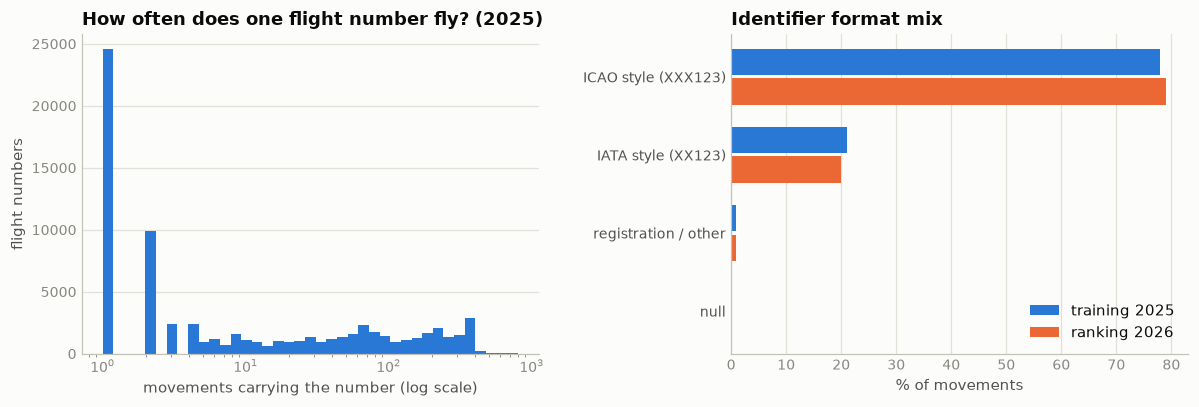

In [20]:
cnts = con.sql(f"""
    SELECT count(*) c FROM {T} WHERE FLIGHT_mvt IS NOT NULL GROUP BY FLIGHT_mvt""").df().c
fmt_mix = con.sql(f"""
    WITH t AS (SELECT {FMT} f, 100.0*count(*)/sum(count(*)) OVER () pct FROM {T} GROUP BY 1),
         r AS (SELECT {FMT} f, 100.0*count(*)/sum(count(*)) OVER () pct FROM {R} GROUP BY 1)
    SELECT coalesce(t.f, r.f) fmt, coalesce(t.pct, 0) pct_t, coalesce(r.pct, 0) pct_r
    FROM t FULL JOIN r USING (f) ORDER BY pct_t""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
bins = np.logspace(0, np.log10(800), 40)
a1.hist(cnts, bins=bins, color=BLUE)
a1.set_xscale("log")
a1.set_title("How often does one flight number fly? (2025)")
a1.set_xlabel("movements carrying the number (log scale)")
a1.set_ylabel("flight numbers")
style(a1)

y = np.arange(len(fmt_mix))
a2.barh(y + 0.19, fmt_mix.pct_t, height=0.34, color=BLUE, label="training 2025")
a2.barh(y - 0.19, fmt_mix.pct_r, height=0.34, color=ORANGE, label="ranking 2026")
a2.set_yticks(y, fmt_mix.fmt, color=INK2)
a2.set_title("Identifier format mix")
a2.set_xlabel("% of movements")
a2.legend(loc="lower right")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- Practically never null (410 rows in training, 97 in ranking). ~74.5k distinct values in 2025;
  the median number appears only **4×** a year, yet the busiest (`UAE81W`, `ITY058`, `SQ026`, …)
  fly ~2× daily, ~730×/year — a heavy-tailed identity, as the log-scale histogram shows.
- Format mix is stable across the two files: ~78% ICAO-callsign style, ~21% IATA style, ~1%
  registrations/other. It literally equals `CALLSIGN_flt` on 73% of matched rows — the two
  columns are near-duplicates, differing mainly in IATA-vs-ICAO spelling.
- **Schedule churn**: 80.7% of ranking departures reuse a 2025 flight number; the other 66,616
  rows (19.3%) carry one of 6,756 numbers never seen in training.
- The identity does carry signal: on frequent numbers, predicting each number's own mean taxi
  beats the airport mean, RMSE 344 → 301 s. A flight number bundles airline + route + slot +
  terminal in one token.
- **Use in modeling:** not as a raw high-cardinality category (19% unseen in 2026). Use
  smoothed target/frequency encodings with fallback to coarser identities (operator, route,
  airport), and a "flies under a registration" flag as a GA/bizav marker.

## 4 · `FLIGHT_RULE_mvt` — flight rules: instrument or visual

The docs promise three values — `I` = IFR, `V` = VFR, `NA` = unknown — but the file uses a real
NULL where the docs say `NA`. At ten major hubs essentially everything flies IFR, so this is less
a category than a **rare-event flag**: who on earth flies *visually* out of Schiphol, and does
that change how long they taxi?

Three questions: (1) how rare are `V` and NULL, and is the mix stable into 2026; (2) how does
the rule relate to §2's flight-plan matching (and to its `FLIGHT_RULE_flt` sibling, which has
extra `Y`/`Z` mixed-rule codes); (3) does the rule carry taxi-time signal.

In [21]:
display(cat_stats("FLIGHT_RULE_mvt"))

con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅ null') "rule",
           count(*) FILTER (src = 't' AND PHASE_mvt = 'DEP') t_dep,
           count(*) FILTER (src = 't' AND PHASE_mvt = 'ARR') t_arr,
           count(*) FILTER (src = 'r' AND PHASE_mvt = 'DEP') r_dep,
           count(*) FILTER (src = 'r' AND PHASE_mvt = 'ARR') r_arr,
           round(100.0 * count(*) FILTER (src = 't')
                 / sum(count(*) FILTER (src = 't')) OVER (), 3) pct_train,
           round(100.0 * count(*) FILTER (src = 'r')
                 / sum(count(*) FILTER (src = 'r')) OVER (), 3) pct_rank
    FROM (SELECT 't' src, PHASE_mvt, FLIGHT_RULE_mvt FROM {T}
          UNION ALL SELECT 'r', PHASE_mvt, FLIGHT_RULE_mvt FROM {R})
    GROUP BY 1 ORDER BY t_dep DESC""").df()

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,689,0.02,2
ranking 2026,689534,84,0.01,2


,rule,t_dep,t_arr,r_dep,r_arr,pct_train,pct_rank
0,I,2081914,2079115,344402,344150,99.838,99.858
1,V,2930,3149,419,479,0.146,0.130
2,∅ null,203,486,20,64,0.017,0.012


In [22]:
# how the rule interacts with the flight-plan match of §2
print("share of movements without a flight-plan match, by rule:")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅') "rule", count(*) n,
           round(100.0 * count(*) FILTER (FLIGHT_ID_mvt IS NULL) / count(*), 1) pct_unmatched
    FROM {T} GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nmatched rows — FLIGHT_RULE_mvt vs FLIGHT_RULE_flt:")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_mvt, '∅') mvt, coalesce(FLIGHT_RULE_flt, '∅') flt, count(*) n
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1, 2 ORDER BY n DESC""").df().to_string(index=False))

print("\nmedian DEP taxi by FLIGHT_RULE_flt (matched, 1–3600 s):")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_flt, '∅') flt, count(*) n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC""").df().to_string(index=False))

print("\nthe 689 null-rule rows — what the flight plan says (DEP | ARR):")
print(con.sql(f"""
    SELECT coalesce(FLIGHT_RULE_flt, '(unmatched)') flt,
           count(*) FILTER (PHASE_mvt = 'DEP') dep,
           count(*) FILTER (PHASE_mvt = 'ARR') arr
    FROM {T} WHERE FLIGHT_RULE_mvt IS NULL GROUP BY 1 ORDER BY dep DESC""").df().to_string(index=False))

share of movements without a flight-plan match, by rule:
rule       n  pct_unmatched
   I 4161029            0.6
   V    6079          100.0
   ∅     689           14.9

matched rows — FLIGHT_RULE_mvt vs FLIGHT_RULE_flt:
mvt flt       n
  I   I 4126828
  I   ∅    7129
  I   Y    1425
  I   Z     895
  ∅   I     432
  ∅   Y      79
  ∅   Z      74
  I   V       4
  ∅   ∅       1

median DEP taxi by FLIGHT_RULE_flt (matched, 1–3600 s):
flt       n  med_taxi
  I 2057904     911.0
  Y    1414     654.0
  ∅     120     661.5
  Z       5     563.0
  V       4     412.5

the 689 null-rule rows — what the flight plan says (DEP | ARR):
        flt  dep  arr
          I   84  348
          Y   79    0
(unmatched)   40   64
          Z    0   74


top VFR departure identities (ICAO-style callsigns, training):
pfx  typ   ap   n
ZXP A139 EHAM 845
NCG DH8A EHAM 544
ICC C208 LEBL 134
FCK B350 EDDF  15
RGA A109 LSZH   8
BPO AS32 EDDM   6


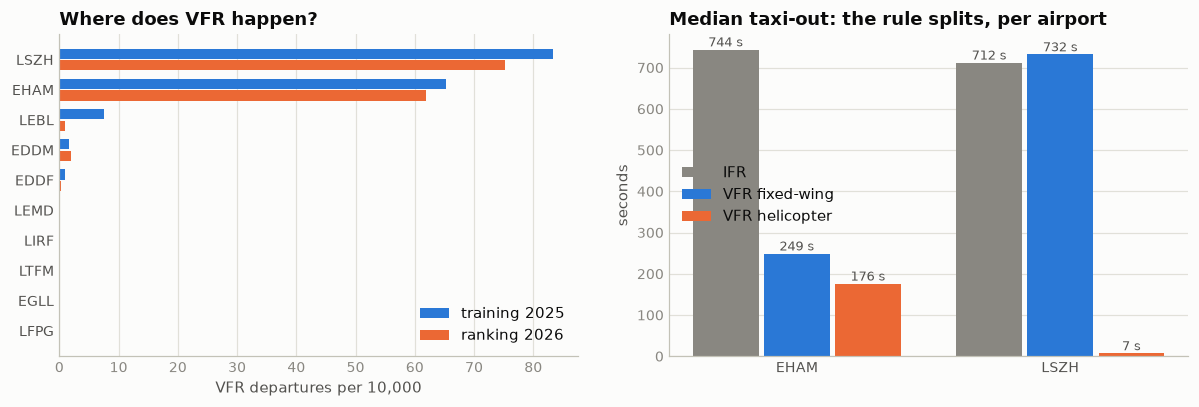

RMSE on the 2,692 VFR departures: airport mean 543.6 s → airport × VFR × heli mean 273.6 s


In [23]:
# who flies VFR at a top-10 hub, and how do they taxi?
VFR_ID = "regexp_matches(FLIGHT_mvt, '^[A-Z]{3}[0-9]')"
HELI = ("('A139','A109','A169','A189','AS32','AS50','B06','B407','B429','B505',"
        "'EC20','EC35','EC45','EC55','H145','H160','R44','S76')")

print("top VFR departure identities (ICAO-style callsigns, training):")
print(con.sql(f"""
    SELECT substr(FLIGHT_mvt, 1, 3) pfx, mode(AIRCRAFT_TYPE_mvt) typ, mode(ADEP_mvt) ap, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_RULE_mvt = 'V' AND {VFR_ID}
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

vfr_rate = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, 1e4 * count(*) FILTER (FLIGHT_RULE_mvt = 'V') / count(*) r
               FROM {T} WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, 1e4 * count(*) FILTER (FLIGHT_RULE_mvt = 'V') / count(*) r
               FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, t.r rate_t, r.r rate_r FROM t JOIN r USING (ap) ORDER BY rate_t""").df()

med = con.sql(f"""
    SELECT ADEP_mvt ap,
           CASE WHEN FLIGHT_RULE_mvt = 'I' THEN 'IFR'
                WHEN AIRCRAFT_TYPE_mvt IN {HELI} THEN 'VFR helicopter'
                ELSE 'VFR fixed-wing' END grp,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt IN ('EHAM', 'LSZH')
      AND FLIGHT_RULE_mvt IS NOT NULL AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1, 2""").df()

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(vfr_rate))
a1.barh(y + 0.19, vfr_rate.rate_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, vfr_rate.rate_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, vfr_rate.ap, color=INK2)
a1.set_title("Where does VFR happen?")
a1.set_xlabel("VFR departures per 10,000")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)

d = med.set_index(["ap", "grp"]).med
x = np.arange(2)
for i, (g, c) in enumerate([("IFR", MUTED), ("VFR fixed-wing", BLUE), ("VFR helicopter", ORANGE)]):
    bars = a2.bar(x + (i - 1) * 0.27, [d.get(("EHAM", g)), d.get(("LSZH", g))],
                  width=0.25, color=c, label=g)
    a2.bar_label(bars, fmt="%.0f s", fontsize=8.5, color=INK2)
a2.set_xticks(x, ["EHAM", "LSZH"], color=INK2)
a2.set_title("Median taxi-out: the rule splits, per airport")
a2.set_ylabel("seconds")
a2.legend()
style(a2)
fig.tight_layout(w_pad=2.5)
plt.show()

# signal check on the rows the flag actually touches
sig = con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, FLIGHT_RULE_mvt fr,
                      CASE WHEN AIRCRAFT_TYPE_mvt IN {HELI} THEN 'h' ELSE 'f' END k,
                      TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         apm AS (SELECT ap, avg(y) m FROM d GROUP BY 1),
         grp AS (SELECT ap, k, avg(y) m FROM d WHERE fr = 'V' GROUP BY 1, 2)
    SELECT count(*), round(sqrt(avg((y - apm.m)^2)), 1), round(sqrt(avg((y - grp.m)^2)), 1)
    FROM d JOIN apm USING (ap) JOIN grp USING (ap, k) WHERE fr = 'V'""").fetchone()
print(f"RMSE on the {sig[0]:,} VFR departures: airport mean {sig[1]} s → airport × VFR × heli mean {sig[2]} s")

**Findings**

- Practically constant: **99.85% `I`**, 0.14% `V` (6,079 movements in 2025), and 689 true NULLs —
  the `NA` the docs promise never appears as a string. The mix is the same in the ranking file;
  419 of our 344,841 predictions are VFR departures.
- **`V` ⇒ unmatched, without a single exception.** NM flight plans are an IFR affair: all 6,079
  VFR movements have no `FLIGHT_ID_mvt` and a fully NULL `_flt` block. This is the "excused"
  slice of §2's unmatched population — §2b/2c's twin recovery deliberately chased unmatched
  *IFR* only, so for VFR rows the `_flt` features are *structurally* missing, and the
  "no flight plan" indicator should stay TRUE for them.
- Where a plan is matched the two rule columns agree; the `_flt` side is just finer. 2,320
  matched movements are `Y`/`Z` (rule change en route) that `_mvt` flattens to `I`, and they
  taxi shorter (median 654 s vs 911 s for pure IFR departures). The 689 NULLs are 85% *matched*
  rows, so `FLIGHT_RULE_flt` backfills most of them — and 79 of the 203 DEP NULLs are `Y`,
  i.e. the airport system chokes disproportionately on mixed-rule plans.
- VFR at a top-10 hub means **special-mission fleets at two airports**: EHAM (65/10k — `ZXP`
  AW139 helicopters and `NCG` coastguard Dash-8s) and LSZH (83/10k — HB-registered light
  singles plus `RGA` Rega helicopters), a sprinkle at LEBL/EDDM/EDDF (`ICC` Cessna Caravans at
  LEBL), and literally zero at LTFM, LFPG, EGLL, LIRF. The same fleets show up in 2026.
- The flag is a big lever *on its own rows*, in opposite directions per airport: at EHAM,
  VFR lifts after a median 176 s (heli) / 249 s (fixed-wing) against 744 s for IFR, while at
  LSZH fixed-wing VFR taxis like an airliner (732 s) and helicopters barely taxi at all
  (median **7 s** — Rega departs from its own base). Predicting VFR rows with an
  airport × heli mean instead of the airport mean cuts their RMSE 544 → 274 s.
- **Use in modeling:** feed the model `coalesce(FLIGHT_RULE_mvt, FLIGHT_RULE_flt)` (keeping
  `Y`/`Z` distinct) plus an is-helicopter flag from `AIRCRAFT_TYPE_mvt`, and let them interact
  with airport. Only ~0.12% of ranking rows are VFR, so the total-RMSE gain is small (well
  under 1 s) — but it is free, and these are exactly the rows where an IFR-trained model is
  embarrassing (a 12-minute taxi predicted for a helipad departure).

### 4a · Addendum — the 689 rows with no rule at all

§4 parked them; here we ask whether the NULLs are noise or structure. 689 training rows and 84
ranking rows (20 of them predictions) carry no `FLIGHT_RULE_mvt`. Three questions: are they
random (a logging hiccup) or a particular kind of traffic; can the rule be recovered — from the
matched plan, from the identity's history, or from the airframe; and should the pipeline care?

In [24]:
NLL = f"(SELECT *, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub FROM {T} WHERE FLIGHT_RULE_mvt IS NULL)"

print("null-rule rows by hub × phase × what the matched plan says:")
print(con.sql(f"""
    SELECT hub, PHASE_mvt ph, coalesce(FLIGHT_RULE_flt, '(unmatched)') flt, count(*) n
    FROM {NLL} GROUP BY 1, 2, 3 ORDER BY hub, ph, n DESC""").df().to_string(index=False))

print("\nwho loses the flag? market segment, null rows vs the whole file:")
print(con.sql(f"""
    WITH a AS (SELECT MARKET_SEGMENT_flt seg, count(*) n FROM {NLL} GROUP BY 1),
         b AS (SELECT MARKET_SEGMENT_flt seg, count(*) n FROM {T} GROUP BY 1)
    SELECT coalesce(a.seg, '(unmatched)') seg, a.n,
           round(100.0 * a.n / sum(a.n) OVER (), 1) pct_of_nulls,
           round(100.0 * b.n / sum(b.n) OVER (), 1) pct_of_all
    FROM a JOIN b ON a.seg IS NOT DISTINCT FROM b.seg ORDER BY a.n DESC""").df().to_string(index=False))

print("\nnull count by date — one date dominates:")
print(con.sql(f"""
    SELECT MVT_TIME_UTC_mvt::DATE d, count(*) n, mode(hub) hub FROM {NLL}
    GROUP BY 1 ORDER BY n DESC LIMIT 4""").df().to_string(index=False))

print("\nEHAM on 20 July 2025, hour by hour — the flag drops for part of the afternoon:")
print(con.sql(f"""
    SELECT hour(MVT_TIME_UTC_mvt) h, count(*) mvts,
           count(*) FILTER (FLIGHT_RULE_mvt IS NULL) n_null
    FROM {T}
    WHERE (CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END) = 'EHAM'
      AND MVT_TIME_UTC_mvt::DATE = DATE '2025-07-20'
    GROUP BY 1 ORDER BY 1""").df().set_index("h").T.to_string())

null-rule rows by hub × phase × what the matched plan says:
 hub  ph         flt   n
EDDF ARR           Z  72
EDDF ARR           I  24
EDDF ARR (unmatched)  20
EDDF DEP           Y  79
EDDF DEP (unmatched)  15
EDDF DEP           I   3
EDDM ARR           I  70
EDDM ARR (unmatched)   2
EDDM DEP           I   4
EHAM ARR           I 254
EHAM ARR (unmatched)  42
EHAM ARR           Z   2
EHAM DEP           I  77
EHAM DEP (unmatched)  25

who loses the flag? market segment, null rows vs the whole file:
          seg   n  pct_of_nulls  pct_of_all
     Business 260          37.7         2.1
     Mainline 166          24.1        63.6
  (unmatched) 104          15.1         0.9
     Regional  80          11.6        10.2
      Lowcost  40           5.8        19.2
Non-Scheduled  12           1.7         0.7
        Cargo  11           1.6         2.9
        Other  10           1.5         0.4
     Military   6           0.9         0.0

null count by date — one date dominates:
         d   n  h

In [25]:
# the 104 unmatched nulls, and how far history can carry the rest
print("unmatched null-rule rows — top airframes and the identities they fly under:")
print(con.sql(f"""
    SELECT AIRCRAFT_TYPE_mvt typ, count(*) n,
           substr(string_agg(DISTINCT FLIGHT_mvt, ', '), 1, 48) ids
    FROM {NLL} WHERE FLIGHT_ID_mvt IS NULL GROUP BY 1 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nrecovery accounting (training):")
print(con.sql(f"""
    WITH hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM {T}
                  WHERE FLIGHT_RULE_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
         vote AS (SELECT FLIGHT_mvt, arg_max(r, c) r FROM hist GROUP BY 1)
    SELECT CASE
        WHEN FLIGHT_RULE_flt = 'I' THEN '1 · plan says I'
        WHEN FLIGHT_RULE_flt = 'Y' AND PHASE_mvt = 'DEP' THEN '2 · Y dep (IFR at the hub)'
        WHEN FLIGHT_RULE_flt = 'Z' AND PHASE_mvt = 'ARR' THEN '2 · Z arr (IFR at the hub)'
        WHEN v.r IS NOT NULL THEN '3 · history vote → ' || v.r
        ELSE '4 · unknown' END bucket, count(*) n
    FROM {NLL} LEFT JOIN vote v USING (FLIGHT_mvt) GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nhow unanimous are the history votes?")
print(con.sql(f"""
    WITH ids AS (SELECT DISTINCT FLIGHT_mvt FROM {NLL}
                 WHERE FLIGHT_RULE_flt IS NULL AND FLIGHT_mvt IS NOT NULL),
         hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM {T}
                  WHERE FLIGHT_RULE_mvt IS NOT NULL AND FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
         agg AS (SELECT FLIGHT_mvt, arg_max(r, c) r, sum(c) tot, max(c) top FROM hist GROUP BY 1)
    SELECT r vote, count(*) identities, round(avg(100.0 * top / tot), 1) avg_purity_pct,
           min(tot) min_history, max(tot) max_history
    FROM ids JOIN agg USING (FLIGHT_mvt) GROUP BY 1""").df().to_string(index=False))

unmatched null-rule rows — top airframes and the identities they fly under:
 typ  n                                              ids
EH10 13              ZK001, ZJ995, ZJ995A, ZJ119, ZK001A
PC12 11 JFA047Z, YY98242, JFA014H, YY98352, YY98542, YY9
A139 11 ZXP24B, NCG04A, ZXP24A, ZXP24C, ZXP25Z, ZXP25B, 
LYNX  7                   AAC101, AAC102, AAC103, AAC105
PC24  6 DCJMS, FYL024V, FYL081G, DCOIN1, FYL021G, FYL023
 S61  6                                     NH60B, NH60A
AS32  5                              S455A, S449A, S441A
PRM1  4               YY98262, YY98961, YY98306, YY98162

recovery accounting (training):
                    bucket   n
           1 · plan says I 432
2 · Y dep (IFR at the hub)  79
2 · Z arr (IFR at the hub)  74
      3 · history vote → I  38
      3 · history vote → V  25
               4 · unknown  41

how unanimous are the history votes?
vote  identities  avg_purity_pct  min_history  max_history
   V          17            94.2          1.0        639.0
   I 

In [26]:
# recover every null (training + ranking) with provenance -> data/derived/rule_recovered.parquet
# §4's HELI list + the military/SAR rotorcraft seen above (types the excused VFR fleet never uses)
HELI_ALL = HELI[:-1] + ",'EH10','LYNX','S61','S92','H47','NH90','PUMA')"

rec = con.sql(f"""
    WITH pool AS (
        SELECT MVT_ID_mvt, 'training' dataset, PHASE_mvt, FLIGHT_mvt, FLIGHT_RULE_flt,
               AIRCRAFT_TYPE_mvt FROM {T} WHERE FLIGHT_RULE_mvt IS NULL
        UNION ALL
        SELECT MVT_ID_mvt, 'ranking', PHASE_mvt, FLIGHT_mvt, FLIGHT_RULE_flt,
               AIRCRAFT_TYPE_mvt FROM {R} WHERE FLIGHT_RULE_mvt IS NULL),
    hist AS (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt r, count(*) c FROM
                 (SELECT FLIGHT_mvt, FLIGHT_RULE_mvt FROM {T} WHERE FLIGHT_RULE_mvt IS NOT NULL
                  UNION ALL
                  SELECT FLIGHT_mvt, FLIGHT_RULE_mvt FROM {R} WHERE FLIGHT_RULE_mvt IS NOT NULL)
             WHERE FLIGHT_mvt IS NOT NULL GROUP BY 1, 2),
    vote AS (SELECT FLIGHT_mvt, arg_max(r, c) r FROM hist GROUP BY 1)
    SELECT MVT_ID_mvt, dataset,
           CASE WHEN FLIGHT_RULE_flt IS NOT NULL THEN FLIGHT_RULE_flt
                WHEN v.r IS NOT NULL THEN v.r
                WHEN AIRCRAFT_TYPE_mvt IN {HELI_ALL} THEN 'V' ELSE 'I' END rule_rec,
           CASE WHEN FLIGHT_RULE_flt IS NOT NULL THEN 'flt'
                WHEN v.r IS NOT NULL THEN 'history_vote'
                ELSE 'type_guess' END rule_src
    FROM pool LEFT JOIN vote v USING (FLIGHT_mvt)""").df()

out = ROOT / "data/derived/rule_recovered.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "rule_src"]).rule_rec.value_counts().unstack(fill_value=0))

wrote 773 rows → data/derived/rule_recovered.parquet
rule_rec                 I   V   Y   Z
dataset  rule_src                     
ranking  flt            47   0   8   6
         history_vote   11   3   0   0
         type_guess      9   0   0   0
training flt           432   0  79  74
         history_vote   38  25   0   0
         type_guess     17  24   0   0


**Addendum findings**

- The 689 nulls are three different stories, none of them random:
  1. **One afternoon at Schiphol** — 185 rows (27%) are EHAM on **20 July 2025**, ~09:00–19:00
     UTC, where the flag silently dropped off part of the stream (up to ~40% of movements in
     the worst hour) while everything else logged normally. Ordinary IFR traffic; the plan
     side says `I` for nearly all of them. EDDM's little pile is the same disease —
     44 of its 76 nulls fall on a single September day.
  2. **Frankfurt's allergy to mixed-rule plans** — EDDF contributes almost no plain-IFR nulls
     (3 DEP rows); its nulls *are* §4's `Y`-departures and `Z`-arrivals. Other airports
     flatten Y/Z to `I`; EDDF writes nothing. Both legs at the hub are technically IFR — but
     keep the codes distinct: §4 showed Y-plans taxi ~4 min shorter than pure IFR.
  3. **Traffic the system barely knows** — Business Aviation is 37.7% of the nulls against
     2.1% of all movements (18× over), and the 104 unmatched nulls are mostly military/SAR
     rotorcraft: UK Merlins flying under `ZJ`/`ZK` airframe serials, Army Air Corps Lynx,
     Sea Kings. The organizers removed military traffic *mostly*.
- **Recovery works in layers**, mirroring §2c: the matched plan names the rule for 585 rows
  (85%); a per-identity majority vote over the year settles another 63 at 94–97% purity; the
  last 41 get a type-based guess (rotorcraft → `V`, else `I`). All of it — training **and**
  the 84 ranking nulls (61 plan / 14 vote / 9 guess) — is saved with provenance to
  `data/derived/rule_recovered.parquet` (773 rows, joined on `MVT_ID_mvt`).
- **Use in modeling:** join the file and take `coalesce(FLIGHT_RULE_mvt, rule_rec)` as the one
  rule feature, levels `I/V/Y/Z`, no missing category left. The direct RMSE stake is 20 DEP
  predictions — negligible; the real value is cleanliness plus the knowledge that rule-nulls
  are **not** missing-at-random: they mark either one harmless EHAM afternoon or genuinely
  odd traffic.

In [27]:
# ---- final accounting: one rule for every movement ----
REC = f"read_parquet('{ROOT}/data/derived/rule_recovered.parquet')"
TWIN = (f"(SELECT MVT_ID_mvt, FLIGHT_RULE_flt frw FROM read_parquet('{ROOT}/data/derived/recovered_flt_blocks.parquet')"
        f" UNION ALL SELECT MVT_ID_mvt, FLIGHT_RULE_flt FROM read_parquet('{ROOT}/data/derived/recovered_flt_relaxed.parquet'))")

# precedence: recovered nulls (4a) · mvt's V (the hub-leg fact) · Y/Z from any plan source
# (refines a flat I) · mvt's I. The twin layers' six Y/Z rows sit on mvt-V movements, so V wins.
FINAL = f"""
    SELECT t.*, CASE
             WHEN t.FLIGHT_RULE_mvt IS NULL THEN rec.rule_rec
             WHEN t.FLIGHT_RULE_mvt = 'V' THEN 'V'
             WHEN coalesce(t.FLIGHT_RULE_flt, w.frw) IN ('Y', 'Z') THEN coalesce(t.FLIGHT_RULE_flt, w.frw)
             ELSE t.FLIGHT_RULE_mvt END rule_final,
           CASE
             WHEN t.FLIGHT_RULE_mvt IS NULL THEN 'was null · ' || rec.rule_src
             WHEN t.FLIGHT_RULE_mvt = 'V' THEN 'mvt says V'
             WHEN coalesce(t.FLIGHT_RULE_flt, w.frw) IN ('Y', 'Z') THEN 'flt Y/Z refines a flat I'
             ELSE 'mvt says I' END prov
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R}) t
    LEFT JOIN {TWIN} w USING (MVT_ID_mvt)
    LEFT JOIN {REC} rec USING (MVT_ID_mvt)"""

left_over = con.sql(f"WITH f AS ({FINAL}) SELECT count(*) FROM f WHERE rule_final IS NULL").fetchone()[0]
print(f"rows still without a rule: {left_over}")
assert left_over == 0

print("\nwhere every movement's rule now comes from:")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT prov, count(*) FILTER (ds = 'training') training, count(*) FILTER (ds = 'ranking') ranking
    FROM f GROUP BY 1 ORDER BY training DESC""").df().to_string(index=False))

print("\nfinal distribution:")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT rule_final, count(*) FILTER (ds = 'training') train_n,
           round(100.0 * count(*) FILTER (ds = 'training') / 4167797, 3) train_pct,
           count(*) FILTER (ds = 'ranking') rank_n,
           count(*) FILTER (ds = 'ranking' AND PHASE_mvt = 'DEP') rank_dep
    FROM f GROUP BY 1 ORDER BY train_n DESC""").df().to_string(index=False))

print("\ntaxi time by final rule (training, 1–3600 s):")
print(con.sql(f"""WITH f AS ({FINAL})
    SELECT PHASE_mvt ph, rule_final, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean,
           quantile_cont(TAXITIME_SEC_mvt, 0.25) p25, quantile_cont(TAXITIME_SEC_mvt, 0.5) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.75) p75
    FROM f WHERE ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1, 2 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

sig = con.sql(f"""WITH f AS ({FINAL}),
    d AS (SELECT ADEP_mvt ap, rule_final rf, TAXITIME_SEC_mvt::DOUBLE y FROM f
          WHERE ds = 'training' AND PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
    apm AS (SELECT ap, avg(y) m FROM d GROUP BY 1),
    grm AS (SELECT ap, rf, avg(y) m FROM d GROUP BY 1, 2)
    SELECT round(sqrt(avg((y - apm.m)^2)), 2), round(sqrt(avg((y - grm.m)^2)), 2)
    FROM d JOIN apm USING (ap) JOIN grm USING (ap, rf)""").fetchone()
print(f"\nRMSE over all training departures: airport mean {sig[0]} s → airport × rule {sig[1]} s")

rows still without a rule: 0

where every movement's rule now comes from:


                    prov  training  ranking
              mvt says I   4158709   688101
              mvt says V      6079      898
flt Y/Z refines a flat I      2320      451
          was null · flt       585       61
 was null · history_vote        63       14
   was null · type_guess        41        9

final distribution:
rule_final  train_n  train_pct  rank_n  rank_dep
         I  4159196     99.794  688168    344172
         V     6128      0.147     901       419
         Y     1504      0.036     264       247
         Z      969      0.023     201         3

taxi time by final rule (training, 1–3600 s):


 ph rule_final       n  mean   p25   med     p75
DEP          I 2076404 982.0 720.0 911.0 1185.00
DEP          V    2710 381.0 124.0 244.5  577.50
DEP          Y    1414 746.0 411.0 654.0 1041.00
DEP          Z       5 500.0 424.0 563.0  575.00
ARR          I 2078021 536.0 324.0 481.0  665.00
ARR          V    3004 268.0 125.0 213.0  316.25
ARR          Z     963 421.0 299.0 381.0  496.00
ARR          Y      85 474.0 260.0 438.0  569.00



RMSE over all training departures: airport mean 346.57 s → airport × rule 346.16 s


**The rule feature, final form**

Coverage is now **100%**: every one of the 4,167,797 training and 689,534 ranking movements
carries a rule, via the precedence *recovered null → `V` from the movement → `Y`/`Z` from any
plan source → `I`*. The movement's `V` outranks the plan on purpose — §2b's six V-flagged twin
recoveries carry `Y`/`Z` plans, but the hub leg was flown visually and that is the fact that
moves taxi time.

| level | training | ranking | …of which DEP (predictions) | median DEP taxi |
|---|---|---|---|---|
| `I` | 4,159,196 (99.794%) | 688,168 | 344,172 | 911 s |
| `V` | 6,128 (0.147%) | 901 | 419 | 244 s |
| `Y` | 1,504 (0.036%) | 264 | 247 | 654 s |
| `Z` | 969 (0.023%) | 201 | 3 | 563 s (n=5) |

- Provenance: raw `_mvt` covers 99.98%; plan-side `Y`/`Z` refines 2,320 + 451 flat `I`s;
  §4a's file supplies the 773 former nulls (646 from the plan, 77 by history vote, 50 guessed).
- The levels are ordered and real on both sides of the operation: DEP medians 911/654/244 s for
  `I`/`Y`/`V`, and on the taxi-in side 481/381/213 s for `I`/`Z`/`V`. `Z` departures are
  near-nonexistent (5 training rows) — the level earns its keep on arrivals.
- Global worth, measured honestly: airport-mean → airport × rule group means moves training
  DEP RMSE by just **−0.4 s** (346.6 → 346.2), all of it concentrated in the 0.2% non-`I`
  rows. A cheap, clean, never-missing categorical — exactly what §4 asked for.
- **Pipeline recipe:** the `CASE` in the cell above, verbatim — inputs are the raw columns plus
  `rule_recovered.parquet` and the two twin-recovery layers, all joined on `MVT_ID_mvt`.

## 5 · `ADEP_mvt` — aerodrome of departure

The ICAO code of the airport the flight departed from — the first column that is a *feature* in
the everyday sense. Its role flips with phase: on `DEP` rows it names the hub whose taxi-out we
predict; on `ARR` rows it is the origin — anywhere on earth — and the hub sits in `ADES_mvt`.
Three questions: (1) **integrity** — nulls (and ICAO's `ZZZZ` "no aerodrome" stand-in), is every departure really at one of the ten hubs,
and does the flight plan's `ADEP_flt` agree; (2) **mix** — how traffic splits across the hubs,
and whether the split holds into Jan/Jul 2026; (3) **signal** — how much taxi-out the airport
alone explains, setting the baseline every later feature must beat.

In [28]:
display(cat_stats("ADEP_mvt"))

# phase-split integrity: on DEP rows the column should be exactly the ten hub codes (APS, §2b)
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n, count(*) FILTER (ADEP_mvt IS NULL) n_null,
           count(DISTINCT ADEP_mvt) n_unique,
           count(*) FILTER (ADEP_mvt NOT IN {APS}) n_not_hub
    FROM (SELECT 'training' src, PHASE_mvt, ADEP_mvt FROM {T}
          UNION ALL SELECT 'ranking', PHASE_mvt, ADEP_mvt FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndoes the matched plan agree? (training, by phase):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n_matched,
           count(*) FILTER (ADEP_flt IS NULL) flt_null,
           count(*) FILTER (ADEP_mvt = ADEP_flt) agree,
           count(*) FILTER (ADEP_mvt != ADEP_flt) disagree
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,84,0.0,1581
ranking 2026,689534,13,0.0,1107


     src  ph       n  n_null  n_unique  n_not_hub
training ARR 2082750      84      1581    1763487
training DEP 2085047       0        10          0
 ranking ARR  344693      13      1107     292935
 ranking DEP  344841       0        10          0

does the matched plan agree? (training, by phase):
 ph  n_matched  flt_null   agree  disagree
ARR    2074244      6943 2042696     24554
DEP    2062623        46 2062577         0


In [29]:
# the ARR side: origin airports, and two sources that sometimes tell different stories
print("top ADEP_mvt ≠ ADEP_flt pairs (training arrivals) — recurring, schedule-level:")
print(con.sql(f"""
    SELECT ADEP_mvt, ADEP_flt, ADES_mvt hub, mode(CALLSIGN_flt) callsign, count(*) n
    FROM {T} WHERE PHASE_mvt = 'ARR' AND FLIGHT_ID_mvt IS NOT NULL AND ADEP_mvt != ADEP_flt
    GROUP BY 1, 2, 3 ORDER BY n DESC LIMIT 10""").df().to_string(index=False))

# "missing" has two spellings: a real NULL, and ICAO's ZZZZ = departed from a place with
# no code at all (helipad, hospital site, ship). AFIL (air-filed plan) never appears.
print("\nnull vs ZZZZ origins, arrivals only (departures have neither):")
print(con.sql(f"""
    SELECT src, count(*) FILTER (ADEP_mvt IS NULL) mvt_null, count(*) FILTER (ADEP_mvt = 'ZZZZ') mvt_zzzz,
           count(*) FILTER (ADEP_flt = 'ZZZZ') flt_zzzz,
           count(*) FILTER (ADEP_mvt = 'AFIL' OR ADEP_flt = 'AFIL') afil
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking', * FROM {R})
    WHERE PHASE_mvt = 'ARR' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nwho they are (training):")
print(con.sql(f"""
    SELECT CASE WHEN ADEP_mvt IS NULL THEN '∅ null' ELSE 'ZZZZ' END kind, ADES_mvt hub,
           count(*) n, count(*) FILTER (FLIGHT_ID_mvt IS NULL) unmatched,
           count(*) FILTER (ADEP_flt IS NOT NULL AND ADEP_flt != 'ZZZZ') flt_names_one,
           mode(AIRCRAFT_TYPE_mvt) typ, mode(MARKET_SEGMENT_flt) seg
    FROM {T} WHERE PHASE_mvt = 'ARR' AND (ADEP_mvt IS NULL OR ADEP_mvt = 'ZZZZ')
    GROUP BY 1, 2 ORDER BY 1, n DESC""").df().to_string(index=False))

print("\norigin tail, and what 2026 adds:")
print(con.sql(f"""
    SELECT count(DISTINCT ADEP_mvt) origins_2025,
           round(100.0 * count(*) FILTER (ADEP_mvt IN {APS}) / count(*), 1) pct_sister_hub
    FROM {T} WHERE PHASE_mvt = 'ARR'""").df().to_string(index=False))
print(con.sql(f"""
    WITH seen AS (SELECT DISTINCT ADEP_mvt FROM {T} WHERE ADEP_mvt IS NOT NULL)
    SELECT count(DISTINCT ADEP_mvt) origins_2026,
           count(*) FILTER (ADEP_mvt NOT IN (SELECT * FROM seen)) unseen_rows,
           count(DISTINCT ADEP_mvt) FILTER (ADEP_mvt NOT IN (SELECT * FROM seen)) unseen_airports
    FROM {R} WHERE PHASE_mvt = 'ARR' AND ADEP_mvt IS NOT NULL""").df().to_string(index=False))

top ADEP_mvt ≠ ADEP_flt pairs (training arrivals) — recurring, schedule-level:
ADEP_mvt ADEP_flt  hub callsign    n
    ETNB     EDDB EGLL  BAW87AM 2430
    LSSB     LFSB LFPG  AFR1393 1037
    OKBK     OKKK EGLL   KAC101  823
    EVRS     EVRA LFPG   BTI8GJ  546
    NTTT     KLAX LFPG     THT8  538
    KBSZ     UCFM LTFM   THY345  390
    TNCA     TNCB EHAM   KLM765  364
    HAAB     LIMC LSZH   ETH736  355
    APPH     YPPH EGLL     QFA9  348
    SKBO     SKCG EHAM   KLM749  346

null vs ZZZZ origins, arrivals only (departures have neither):


     src  mvt_null  mvt_zzzz  flt_zzzz  afil
training        84       111        20     0
 ranking        13        24         6     0

who they are (training):
  kind  hub  n  unmatched  flt_names_one  typ      seg
  ZZZZ LSZH 61         49             10 AS50 Business
  ZZZZ EHAM 45         42              0 A139 Military
  ZZZZ LIRF  4          1              3 F900 Business
  ZZZZ EDDM  1          0              0 C525 Business
∅ null EDDF 68         31             37 PC12 Business
∅ null LTFM  6          0              5 GLF6 Business
∅ null LFPG  5          1              4 PC12 Business
∅ null LIRF  5          1              4 AT45 Military

origin tail, and what 2026 adds:
 origins_2025  pct_sister_hub
         1581            15.3


 origins_2026  unseen_rows  unseen_airports
         1107          162               66


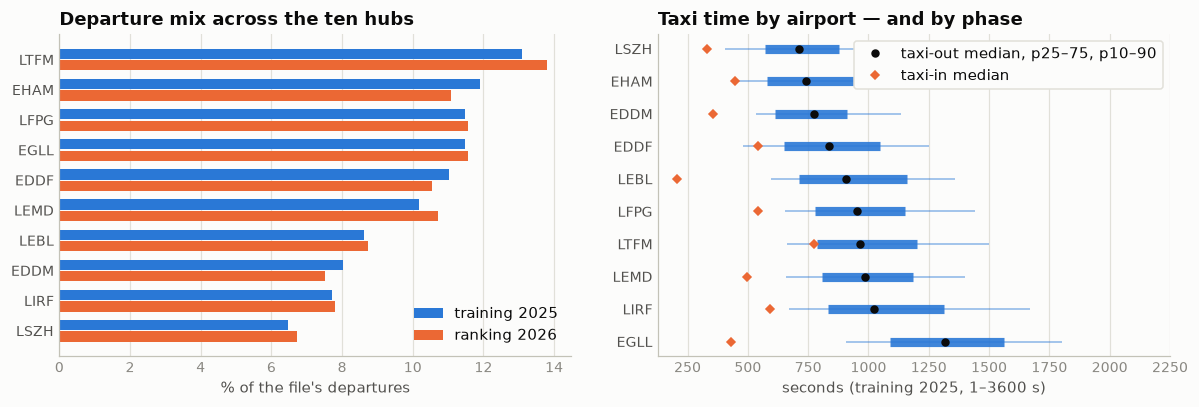

like-for-like traffic: Jan+Jul 2025 vs Jan+Jul 2026 departures per hub:
  ap   n25   n26  delta_pct
EHAM 40949 38182       -6.8
EDDM 27091 25966       -4.2
EDDF 36830 36317       -1.4
EGLL 40210 39840       -0.9
LFPG 39612 39872        0.7
LIRF 26528 26899        1.4
LTFM 46539 47581        2.2
LSZH 22346 23150        3.6
LEBL 28986 30080        3.8
LEMD 35328 36954        4.6


In [30]:
mix = con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, 100.0 * count(*) / sum(count(*)) OVER () s FROM {T}
               WHERE PHASE_mvt = 'DEP' GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, 100.0 * count(*) / sum(count(*)) OVER () s FROM {R}
               WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, t.s share_t, r.s share_r FROM t JOIN r USING (ap) ORDER BY share_t""").df()

taxi = con.sql(f"""
    SELECT ADEP_mvt ap,
           quantile_cont(TAXITIME_SEC_mvt, 0.10) p10, quantile_cont(TAXITIME_SEC_mvt, 0.25) p25,
           quantile_cont(TAXITIME_SEC_mvt, 0.50) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.75) p75, quantile_cont(TAXITIME_SEC_mvt, 0.90) p90
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY med DESC""").df()
taxi_in = con.sql(f"""
    SELECT ADES_mvt ap, quantile_cont(TAXITIME_SEC_mvt, 0.5) med FROM {T}
    WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 GROUP BY 1""").df().set_index("ap").med

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(mix))
a1.barh(y + 0.19, mix.share_t, height=0.34, color=BLUE, label="training 2025")
a1.barh(y - 0.19, mix.share_r, height=0.34, color=ORANGE, label="ranking 2026")
a1.set_yticks(y, mix.ap, color=INK2)
a1.set_title("Departure mix across the ten hubs")
a1.set_xlabel("% of the file's departures")
a1.legend(loc="lower right")
style(a1, x_grid=True, y_grid=False)

y = np.arange(len(taxi))
a2.hlines(y, taxi.p10, taxi.p90, color=BLUE, lw=1.2, alpha=0.45)
a2.hlines(y, taxi.p25, taxi.p75, color=BLUE, lw=6, alpha=0.9)
a2.plot(taxi.med, y, "o", color=INK, ms=4.5, zorder=3, label="taxi-out median, p25–75, p10–90")
a2.plot(taxi_in[taxi.ap].values, y, "D", color=ORANGE, ms=4, label="taxi-in median")
a2.set_yticks(y, taxi.ap, color=INK2)
a2.set_title("Taxi time by airport — and by phase")
a2.set_xlabel("seconds (training 2025, 1–3600 s)")
a2.set_xlim(right=2250)
a2.legend(loc="upper right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

print("like-for-like traffic: Jan+Jul 2025 vs Jan+Jul 2026 departures per hub:")
print(con.sql(f"""
    WITH t AS (SELECT ADEP_mvt ap, count(*) n25 FROM {T}
               WHERE PHASE_mvt = 'DEP' AND month(MVT_TIME_UTC_mvt) IN (1, 7) GROUP BY 1),
         r AS (SELECT ADEP_mvt ap, count(*) n26 FROM {R} WHERE PHASE_mvt = 'DEP' GROUP BY 1)
    SELECT ap, n25, n26, round(100.0 * (n26 - n25) / n25, 1) delta_pct
    FROM t JOIN r USING (ap) ORDER BY delta_pct""").df().to_string(index=False))

In [31]:
# how much does the airport alone explain?
sig = con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, TAXITIME_SEC_mvt::DOUBLE y FROM {T}
               WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         g AS (SELECT avg(y) m FROM d),
         a AS (SELECT ap, avg(y) am FROM d GROUP BY 1)
    SELECT round(sqrt(avg((y - g.m)^2)), 1), round(sqrt(avg((y - a.am)^2)), 1)
    FROM d CROSS JOIN g JOIN a USING (ap)""").fetchone()
print(f"RMSE over all training departures (1–3600 s): global mean {sig[0]} s → airport mean {sig[1]} s")

print("\ntaxi-out by hub — and the two ranking months against the 2025 medians:")
print(con.sql(f"""
    SELECT ADEP_mvt ap, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean, round(stddev(TAXITIME_SEC_mvt)) sd,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (month(MVT_TIME_UTC_mvt) = 1) med_jan,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) FILTER (month(MVT_TIME_UTC_mvt) = 7) med_jul
    FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY med DESC""").df().to_string(index=False))

# and on the flipped side: does *origin* say anything about taxi-in beyond the hub mean?
sig = con.sql(f"""
    WITH d AS (SELECT ADES_mvt hub, ADEP_mvt org, TAXITIME_SEC_mvt::DOUBLE y FROM {T}
               WHERE PHASE_mvt = 'ARR' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600 AND ADEP_mvt IS NOT NULL),
         hm AS (SELECT hub, avg(y) mh FROM d GROUP BY 1),
         om AS (SELECT hub, org, avg(y) mo FROM d GROUP BY 1, 2 HAVING count(*) >= 200)
    SELECT count(*), round(sqrt(avg((y - hm.mh)^2)), 1), round(sqrt(avg((y - om.mo)^2)), 1)
    FROM d JOIN hm USING (hub) JOIN om USING (hub, org)""").fetchone()
print(f"\ntaxi-in RMSE on the {sig[0]:,} arrivals from frequent origins (≥200/yr): "
      f"hub mean {sig[1]} s → hub × origin mean {sig[2]} s")

RMSE over all training departures (1–3600 s): global mean 388.0 s → airport mean 346.6 s

taxi-out by hub — and the two ranking months against the 2025 medians:
  ap      n   mean    sd    med  med_jan  med_jul
EGLL 238818 1354.0 373.0 1319.0   1260.0   1371.0
LIRF 158737 1117.0 443.0 1022.0    972.0   1090.0
LEMD 212242 1015.0 313.0  985.0    954.0   1002.0
LTFM 272169 1043.0 379.0  963.0    967.0   1011.0
LFPG 239091 1013.0 365.0  954.0    907.0    962.0
LEBL 179699  957.0 331.0  906.0    838.0    945.0
EDDF 230068  862.0 324.0  837.0    825.0    839.0
EDDM 167275  811.0 294.0  774.0    729.0    780.0
EHAM 247866  783.0 311.0  742.0    726.0    751.0
LSZH 134568  741.0 292.0  712.0    706.0    720.0

taxi-in RMSE on the 1,978,608 arrivals from frequent origins (≥200/yr): hub mean 252.6 s → hub × origin mean 234.1 s


**Findings**

- **The departure side is flawless.** Zero nulls, and every one of the 2,085,047 training and
  344,841 ranking departures carries one of the ten hub codes — nothing else, ever, not even ICAO's `ZZZZ`
  stand-in. Where a
  plan is matched, `ADEP_flt` agrees on all 2,062,577 comparable rows (46 plan-side nulls).
  Ten levels, never missing, never unseen: the pipeline's primary categorical.
- On arrivals the same column is the **origin**: 1,580 real airports in 2025 with a long
  tail, and 15.3% of arrivals come from a sister hub. 2026 adds 66 origins never seen in
  training — worth 162 rows, so no encoding worry. **"Missing" comes in two spellings**,
  195 rows in all: 84 true NULLs (the system lost the code — four-fifths EDDF business
  aviation, PC12 shuttles) and 111 `ZZZZ`, ICAO's code for *there is no code*: LSZH and EHAM
  rotorcraft coming in from helipads, hospital sites and ships — §4's special-mission fleets
  again (`ZXP`/`NCG` callsigns), mostly unmatched, correctly so. The plan side has its own 20
  `ZZZZ`s, and the two sides occasionally fill each other's gap (13 plan-side `ZZZZ`s get a
  name from `_mvt`). No recovery layer needed, since no arrival is
  predicted; the sentinel policy (real code / `OFF_AIRPORT` / `UNKNOWN`) lives in §6a, where
  it touches prediction rows, and its waterfall can be pointed at origins if ever needed.
- The two sources disagree on 24,554 arrivals (1.2% of matched) in 1,291 recurring
  schedule-level pairs — the same "wrong" code all year, i.e. upstream mapping tables, not
  noise. Two mechanisms: **multi-leg through-flights**, where `_mvt` keeps the commercial
  origin and `_flt` the flown leg (Air Tahiti Nui into LFPG "from" Papeete vs the actual LAX
  leg; Ethiopian's Addis→Milan→Zurich; KLM's Caribbean tag flights), and **garbled or stale
  codes**, mostly on the `_mvt` side (BA's Berlin traffic lands at EGLL "from" the
  military-prefix `ETNB`; Riga's little Spilve field `EVRS` stands in for `EVRA`; Bali appears
  under its long-retired `WRRR`) — though not always: Kuwait Airways' *plans* still file the
  retired `OKKK` against `_mvt`'s current `OKBK`. Where origin matters, prefer the plan's word.
- **Traffic mix:** LTFM 13.1% down to LSZH 6.5%, and the split holds into 2026 — like-for-like
  (Jan+Jul '25 → Jan+Jul '26) the movers are EHAM −6.8% and EDDM −4.2% against LEMD +4.6%,
  LEBL +3.8%, LSZH +3.6%. No airport enters or leaves.
- **The anchor feature.** Median taxi-out runs 712 s (LSZH) to 1,319 s (EGLL) — Heathrow's
  *25th percentile* (1,088 s) beats every other hub's median. The ten-way split alone moves
  training DEP RMSE **388.0 → 346.6 s**, the reference every later feature must improve on.
  Within-airport spread remains the whole problem: sd 292–443 s, LIRF widest
  (p10–p90 ≈ 670–1,670 s).
- The phase flip is real in the target, not just the schema. Taxi-in has its own, different
  ordering — LEBL: 906 s out vs 207 s in; EGLL: 1,319 vs 428 — and *origin* carries taxi-in
  signal beyond the hub mean (252.6 → 234.1 s RMSE; stand/terminal allocation, presumably).
  Arrival rows have structure worth mining later for stand/terminal proxies, even though we
  never predict them.
- July runs longer than January at **every** hub (EGLL 1,371 vs 1,260 s) — and Jan+Jul is
  exactly what we predict. Noted here; owned by the time columns' sections to come.
- **Use in modeling:** `ADEP_mvt` on DEP rows is *the* airport feature and the interaction
  partner for nearly everything, past (§4's rule) and future (aircraft class, hour of day).
  Nothing to clean, recover, or encode defensively — a rare treat in this file. If origin is
  ever used
  on ARR rows, take `coalesce(nullif(ADEP_flt, 'ZZZZ'), nullif(ADEP_mvt, 'ZZZZ'))` — the plan
  first on the garble pairs' evidence, with the sentinel folded back into NULL.

## 6 · `ADES_mvt` — aerodrome of destination

§5's mirror: on `ARR` rows this names the hub; on `DEP` rows — the rows we predict — it is
the destination, anywhere on earth. And §5's sentinel lesson lands on prediction rows here:
122 + 92 training and 13 + 16 ranking departures carry a ∅ or `ZZZZ` destination. Four
questions: (1) **integrity** — the full sentinel set (∅ / `ZZZZ` / `AFIL`) this time, and is
every arrival's destination a hub; (2) **agreement** — does the plan tell the same story
(through-flights and garbles again, plus this side's own wrinkle: diversions, where
`ADES_FILED_flt` and `ADES_flt` part ways); (3) **signal** — what the destination knows about
taxi-out; (4) **recovery** (§6a) — one destination for every departure: real code,
`OFF_AIRPORT`, or `UNKNOWN`.

In [32]:
display(cat_stats("ADES_mvt"))

# the full sentinel set this time: NULL, ZZZZ ("no such aerodrome"), AFIL (air-filed plan)
print(con.sql(f"""
    SELECT src, PHASE_mvt ph, count(*) n,
           count(*) FILTER (ADES_mvt IS NULL) n_null,
           count(*) FILTER (ADES_mvt = 'ZZZZ') n_zzzz,
           count(*) FILTER (ADES_mvt = 'AFIL') n_afil,
           count(DISTINCT ADES_mvt) n_unique,
           count(*) FILTER (PHASE_mvt = 'ARR' AND ADES_mvt NOT IN {APS}) arr_not_hub
    FROM (SELECT 'training' src, PHASE_mvt, ADES_mvt FROM {T}
          UNION ALL SELECT 'ranking', PHASE_mvt, ADES_mvt FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\ndoes the matched plan agree? (training, by phase):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n_matched,
           count(*) FILTER (ADES_flt IS NULL) flt_null,
           count(*) FILTER (ADES_mvt = ADES_flt) agree,
           count(*) FILTER (ADES_mvt != ADES_flt) disagree
    FROM {T} WHERE FLIGHT_ID_mvt IS NOT NULL GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,122,0.0,1568
ranking 2026,689534,13,0.0,1105


     src  ph       n  n_null  n_zzzz  n_afil  n_unique  arr_not_hub
training ARR 2082750       0       0       0        10            0
training DEP 2085047     122      92       0      1568            0
 ranking ARR  344693       0       0       0        10            0
 ranking DEP  344841      13      16       0      1105            0

does the matched plan agree? (training, by phase):


 ph  n_matched  flt_null   agree  disagree
ARR    2074244      6943 2067301         0
DEP    2062623        46 2033337     29160


In [33]:
# §5's two mechanisms mirrored outbound — plus Turkish Airlines' tag flights joining the party
print("top ADES_mvt ≠ ADES_flt pairs (training departures):")
print(con.sql(f"""
    SELECT ADES_mvt, ADES_flt, ADEP_mvt hub, mode(CALLSIGN_flt) callsign, count(*) n
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL AND ADES_mvt != ADES_flt
    GROUP BY 1, 2, 3 ORDER BY n DESC LIMIT 12""").df().to_string(index=False))

print("\ndiversions (ADES_flt ≠ ADES_FILED_flt) — which story does the movement side tell?")
print(con.sql(f"""
    SELECT count(*) FILTER (ADES_flt != ADES_FILED_flt) diverted,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt = ADES_FILED_flt) mvt_says_filed,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt = ADES_flt) mvt_says_actual,
           count(*) FILTER (ADES_flt != ADES_FILED_flt AND ADES_mvt NOT IN (ADES_flt, ADES_FILED_flt)) mvt_third
    FROM {T} WHERE PHASE_mvt = 'DEP' AND FLIGHT_ID_mvt IS NOT NULL
      AND ADES_flt IS NOT NULL AND ADES_FILED_flt IS NOT NULL AND ADES_mvt IS NOT NULL""").df().to_string(index=False))

print("\nthe departure destination space, and what 2026 adds:")
print(con.sql(f"""
    SELECT count(DISTINCT ADES_mvt) dests_2025,
           round(100.0 * count(*) FILTER (ADES_mvt IN {APS}) / count(*), 1) pct_sister_hub
    FROM {T} WHERE PHASE_mvt = 'DEP'""").df().to_string(index=False))
print(con.sql(f"""
    WITH seen AS (SELECT DISTINCT ADES_mvt FROM {T} WHERE ADES_mvt IS NOT NULL)
    SELECT count(DISTINCT ADES_mvt) dests_2026,
           count(*) FILTER (ADES_mvt NOT IN (SELECT * FROM seen)) unseen_rows,
           count(DISTINCT ADES_mvt) FILTER (ADES_mvt NOT IN (SELECT * FROM seen)) unseen_dests
    FROM {R} WHERE PHASE_mvt = 'DEP' AND ADES_mvt IS NOT NULL""").df().to_string(index=False))

top ADES_mvt ≠ ADES_flt pairs (training departures):
ADES_mvt ADES_flt  hub callsign    n
    ETNB     EDDB EGLL  BAW986G 2426
    LSSB     LFSB LFPG  AFR1192 1016
    OKBK     OKKK EGLL   KAC102  815
    NTTT     KLAX LFPG     THT7  548
    EVRS     EVRA LFPG   BTI69R  545
    MMUN     MMMX LTFM   THY184  486
    HUEN     HRYR LTFM   THY50K  362
    MPTO     SKBO LTFM   THY801  362
    SAEZ     SBGR LTFM    THY15  356
    HAAB     LIMC LSZH   ETH737  354
    APPH     YPPH EGLL    QFA10  352
    ZGGG     UAAA LTFM  THY6538  333

diversions (ADES_flt ≠ ADES_FILED_flt) — which story does the movement side tell?
 diverted  mvt_says_filed  mvt_says_actual  mvt_third
     2070            1397              641         32

the departure destination space, and what 2026 adds:
 dests_2025  pct_sister_hub
       1568            15.3
 dests_2026  unseen_rows  unseen_dests
       1105          174            62


 rmse_airport  rmse_plus_country  rmse_plus_dest
        346.6              326.5           322.4


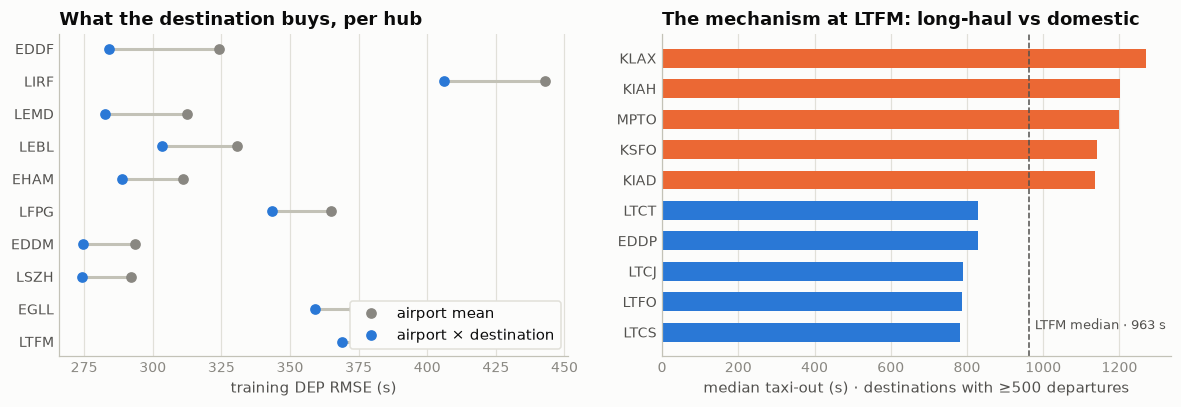

In [34]:
# does knowing where you're headed tell you how long you'll taxi?
print(con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, ADES_mvt de, substr(ADES_mvt, 1, 2) cc, TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'),
         am AS (SELECT ap, avg(y) m FROM d GROUP BY 1),
         cm AS (SELECT ap, cc, avg(y) m FROM d GROUP BY 1, 2 HAVING count(*) >= 200),
         dm AS (SELECT ap, de, avg(y) m FROM d GROUP BY 1, 2 HAVING count(*) >= 200)
    SELECT round(sqrt(avg((y - am.m)^2)), 1) rmse_airport,
           round(sqrt(avg((y - coalesce(cm.m, am.m))^2)), 1) rmse_plus_country,
           round(sqrt(avg((y - coalesce(dm.m, cm.m, am.m))^2)), 1) rmse_plus_dest
    FROM d JOIN am USING (ap) LEFT JOIN cm USING (ap, cc) LEFT JOIN dm USING (ap, de)""").df().to_string(index=False))

gain = con.sql(f"""
    WITH d AS (SELECT ADEP_mvt ap, ADES_mvt de, TAXITIME_SEC_mvt::DOUBLE y
               FROM {T} WHERE PHASE_mvt = 'DEP' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
                 AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'),
         am AS (SELECT ap, avg(y) m FROM d GROUP BY 1),
         dm AS (SELECT ap, de, avg(y) m FROM d GROUP BY 1, 2 HAVING count(*) >= 200)
    SELECT ap, round(sqrt(avg((y - am.m)^2)), 1) r_airport,
           round(sqrt(avg((y - coalesce(dm.m, am.m))^2)), 1) r_dest
    FROM d JOIN am USING (ap) LEFT JOIN dm USING (ap, de)
    GROUP BY 1 ORDER BY r_airport - r_dest""").df()

lt = con.sql(f"""
    WITH d AS (SELECT ADES_mvt de, TAXITIME_SEC_mvt y FROM {T}
               WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LTFM' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600),
         m AS (SELECT de, count(*) n, quantile_cont(y, 0.5) med FROM d GROUP BY 1 HAVING count(*) >= 500)
    (SELECT * FROM m ORDER BY med DESC LIMIT 5) UNION ALL (SELECT * FROM m ORDER BY med LIMIT 5)
    ORDER BY med""").df()
lt_med = con.sql(f"""
    SELECT quantile_cont(TAXITIME_SEC_mvt, 0.5) FROM {T}
    WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'LTFM' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""").fetchone()[0]

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(gain))
a1.hlines(y, gain.r_dest, gain.r_airport, color=BASELINE, lw=2)
a1.plot(gain.r_airport, y, "o", color=MUTED, ms=6, label="airport mean")
a1.plot(gain.r_dest, y, "o", color=BLUE, ms=6, label="airport × destination")
a1.set_yticks(y, gain.ap, color=INK2)
a1.set_title("What the destination buys, per hub")
a1.set_xlabel("training DEP RMSE (s)")
a1.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a1, x_grid=True, y_grid=False)

y = np.arange(len(lt))
colors = [ORANGE if m > lt_med else BLUE for m in lt.med]
a2.barh(y, lt.med, height=0.62, color=colors)
a2.axvline(lt_med, color=INK2, ls="--", lw=1)
a2.text(lt_med + 15, 0.1, f"LTFM median · {lt_med:.0f} s", color=INK2, fontsize=8.5)
a2.set_yticks(y, lt.de, color=INK2)
a2.set_title("The mechanism at LTFM: long-haul vs domestic")
a2.set_xlabel("median taxi-out (s) · destinations with ≥500 departures")
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- The mirror of §5 holds exactly. On arrivals this column is the hub: ten codes, zero
  sentinels, and the matched plan agrees 2,067,301 times out of 2,067,301 (6,943 plan-side
  nulls). On departures it is a real feature: 1,568 destinations, 15.3% of departures headed
  to a sister hub (the network is symmetric), and 2026 adds only 62 unseen destinations
  (174 rows). The sentinel census — §5's lesson applied — is 122 ∅ + 92 `ZZZZ` in training
  and 13 + 16 in ranking (29 prediction rows); `AFIL` appears nowhere.
- The 29,160 plan disagreements (1.4% of matched departures) are §5's mechanisms viewed
  outbound: the same garbles and through-flights (BA's Berlin rows now *leave* "for" `ETNB`;
  THT7 departs LFPG "for Papeete" against the plan's KLAX leg) plus Turkish Airlines' tag
  network — THY184 leaves Istanbul "for Cancún" while the plan flies the Mexico City leg,
  ditto Kigali→Entebbe, Bogotá→Panama, São Paulo→Buenos Aires, Almaty→Guangzhou. `_mvt`
  speaks the commercial through-destination, `_flt` the flown leg; both are schedule-level
  constants, so we leave the pairs alone and let any encoder learn either dialect.
- **Diversions barely touch this column, and in the right way**: of the 2,070 diverted
  matched departures (`ADES_flt` ≠ `ADES_FILED_flt`), `ADES_mvt` sides with the *filed*
  destination 2:1 (1,397 vs 641). The movement record is mostly a pre-departure fact —
  exactly what a feature should be.
- **The signal is real**: airport mean 346.6 s → +country prefix 326.5 → +destination
  322.4 s training DEP RMSE. Per hub the gain runs from −40 s (EDDF) and −37 (LIRF) down to
  −10 (LTFM), and the mechanism is plain at LTFM: the median departure to `KLAX` taxis
  1,270 s against 782 s for domestic `LTCS` — eight minutes of destination signal inside one
  airport. (Destination is entangled with aircraft size and terminal geography, of course —
  the model, not this ladder, will apportion the credit.)
- **Use in modeling:** destination joins airport as a core categorical. The two-letter
  prefix captures over 80% of the lift at a tiny fraction of the cardinality — keep both
  granularities and let the model choose. §6a below makes the column complete first.

### 6a · Addendum — one destination for every departure

The §5 brainstorm, applied where it counts: 29 prediction rows carry a sentinel destination.
The two sentinels say opposite things, so they get opposite treatment. **∅ is data loss** —
the system dropped a code that exists — and runs §4a's waterfall: plan → per-identity history
vote → rotorcraft/VFR guess → honest `UNKNOWN`. **`ZZZZ` is a statement** — this flight went
where no ICAO code goes (EHAM's coastguard patrols, LSZH's rescue helicopters) — so it is
believed and becomes the level `OFF_AIRPORT`, unless the matched plan names a real aerodrome
(a lazy-entry tail of fixed-wing jets logged `ZZZZ` at the terminal). One design choice needs
evidence rather than taste — should the history vote outrank `OFF_AIRPORT` for `ZZZZ` rows
too? — so it gets a cell.

In [35]:
# the 243 sentinel departures: what each recovery source can offer, by sentinel kind
POOLD = f"""(SELECT 'training' ds, MVT_ID_mvt, ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt, ADES_mvt,
                    coalesce(nullif(ADES_flt, 'ZZZZ'), nullif(ADES_FILED_flt, 'ZZZZ')) plan_dest,
                    coalesce(AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V', FALSE) heli_vfr
             FROM {T} WHERE PHASE_mvt = 'DEP' AND (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ')
             UNION ALL
             SELECT 'ranking', MVT_ID_mvt, ADEP_mvt, FLIGHT_mvt, AIRCRAFT_TYPE_mvt, ADES_mvt,
                    coalesce(nullif(ADES_flt, 'ZZZZ'), nullif(ADES_FILED_flt, 'ZZZZ')),
                    coalesce(AIRCRAFT_TYPE_mvt IN {HELI_ALL} OR FLIGHT_RULE_mvt = 'V', FALSE)
             FROM {R} WHERE PHASE_mvt = 'DEP' AND (ADES_mvt IS NULL OR ADES_mvt = 'ZZZZ'))"""
VOTED = f"""(SELECT FLIGHT_mvt, arg_max(d, c) dest, max(c) top, sum(c) tot FROM
                (SELECT FLIGHT_mvt, ADES_mvt d, count(*) c
                 FROM (SELECT FLIGHT_mvt, PHASE_mvt, ADES_mvt FROM {T}
                       UNION ALL SELECT FLIGHT_mvt, PHASE_mvt, ADES_mvt FROM {R})
                 WHERE PHASE_mvt = 'DEP' AND FLIGHT_mvt IS NOT NULL
                   AND ADES_mvt IS NOT NULL AND ADES_mvt != 'ZZZZ'
                 GROUP BY 1, 2) GROUP BY 1)"""

print(con.sql(f"""
    SELECT ds, CASE WHEN ADES_mvt IS NULL THEN '∅ null' ELSE 'ZZZZ' END kind, count(*) n,
           count(plan_dest) plan_names_one,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NOT NULL) vote_could,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NULL AND heli_vfr) heli_vfr_rest,
           count(*) FILTER (plan_dest IS NULL AND v.dest IS NULL AND NOT heli_vfr) bare
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().to_string(index=False))

print("\nwhere a vote would land the believed-ZZZZ rows — plausible, but it un-says the record:")
print(con.sql(f"""
    SELECT v.dest would_become, ADEP_mvt hub, mode(AIRCRAFT_TYPE_mvt) typ, count(*) n,
           round(avg(100.0 * top / tot), 0) purity_pct
    FROM {POOLD} p JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE ADES_mvt = 'ZZZZ' AND plan_dest IS NULL
    GROUP BY 1, 2 ORDER BY n DESC LIMIT 8""").df().to_string(index=False))

print("\nvote quality on the null rows it actually serves:")
print(con.sql(f"""
    SELECT count(*) n_rows, round(avg(100.0 * top / tot), 1) avg_purity,
           min(tot) min_history, max(tot) max_history
    FROM {POOLD} p JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE ADES_mvt IS NULL AND plan_dest IS NULL""").df().to_string(index=False))

print("\nthe bare remainder — nulls with nothing to recover from:")
print(con.sql(f"""
    SELECT ds, ADEP_mvt hub, coalesce(AIRCRAFT_TYPE_mvt, '∅') typ,
           coalesce(FLIGHT_mvt, '∅') ident, count(*) n
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)
    WHERE plan_dest IS NULL AND v.dest IS NULL AND NOT heli_vfr
    GROUP BY 1, 2, 3, 4 ORDER BY 1 DESC, n DESC""").df().to_string(index=False))

      ds   kind   n  plan_names_one  vote_could  heli_vfr_rest  bare
training   ZZZZ  92              14          58             17     3
training ∅ null 122              80          19              4    19
 ranking   ZZZZ  16               2          13              1     0
 ranking ∅ null  13               7           5              0     1

where a vote would land the believed-ZZZZ rows — plausible, but it un-says the record:
would_become  hub  typ  n  purity_pct
        EHAM EHAM A139 39        89.0
        LSXA LSZH EC30  8        86.0
        LSZO LSZH AS50  5        61.0
        LSGS LSZH AS50  4        92.0
        LSGK LSZH EC20  3        67.0
        LSZM LSZH B429  3        50.0
        LSXU LSZH AS50  2        70.0
        AUSL LSZH M20T  1        33.0

vote quality on the null rows it actually serves:
 n_rows  avg_purity  min_history  max_history
     24        63.3          1.0          7.0

the bare remainder — nulls with nothing to recover from:
      ds  hub  typ   ide

In [36]:
# perform the recovery -> data/derived/dest_recovered.parquet, then account for every departure
rec = con.sql(f"""
    SELECT MVT_ID_mvt, ds dataset,
           CASE WHEN plan_dest IS NOT NULL THEN plan_dest
                WHEN ADES_mvt = 'ZZZZ' THEN 'OFF_AIRPORT'
                WHEN v.dest IS NOT NULL THEN v.dest
                WHEN heli_vfr THEN 'OFF_AIRPORT'
                ELSE 'UNKNOWN' END ades_rec,
           CASE WHEN plan_dest IS NOT NULL THEN 'flt'
                WHEN ADES_mvt = 'ZZZZ' THEN 'zzzz_believed'
                WHEN v.dest IS NOT NULL THEN 'history_vote'
                WHEN heli_vfr THEN 'type_guess'
                ELSE 'unknown' END ades_src
    FROM {POOLD} p LEFT JOIN {VOTED} v USING (FLIGHT_mvt)""").df()

out = ROOT / "data/derived/dest_recovered.parquet"
rec.to_parquet(out, index=False)
print(f"wrote {len(rec):,} rows → {out.relative_to(ROOT)}")
print(rec.groupby(["dataset", "ades_src"]).size().unstack(fill_value=0))

DREC = f"read_parquet('{ROOT}/data/derived/dest_recovered.parquet')"
FINALD = f"""
    SELECT t.*, CASE WHEN t.ADES_mvt IS NULL OR t.ADES_mvt = 'ZZZZ' THEN rec.ades_rec
                     ELSE t.ADES_mvt END dest_final
    FROM (SELECT 'training' ds, * FROM {T} WHERE PHASE_mvt = 'DEP'
          UNION ALL SELECT 'ranking', * FROM {R} WHERE PHASE_mvt = 'DEP') t
    LEFT JOIN {DREC} rec USING (MVT_ID_mvt)"""

left = con.sql(f"WITH f AS ({FINALD}) SELECT count(*) FROM f WHERE dest_final IS NULL").fetchone()[0]
print(f"\ndepartures still without a destination: {left}")
assert left == 0

print("\nthe two synthetic levels, and how they taxi (training, 1–3600 s):")
print(con.sql(f"""WITH f AS ({FINALD})
    SELECT dest_final, count(*) FILTER (ds = 'training') train_n,
           count(*) FILTER (ds = 'ranking') rank_n,
           quantile_cont(TAXITIME_SEC_mvt, 0.5)
               FILTER (ds = 'training' AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600) med_taxi
    FROM f WHERE dest_final IN ('OFF_AIRPORT', 'UNKNOWN') GROUP BY 1""").df().to_string(index=False))

wrote 243 rows → data/derived/dest_recovered.parquet
ades_src  flt  history_vote  type_guess  unknown  zzzz_believed
dataset                                                        
ranking     9             5           0        1             14
training   94            19           4       19             78



departures still without a destination: 0

the two synthetic levels, and how they taxi (training, 1–3600 s):
 dest_final  train_n  rank_n  med_taxi
    UNKNOWN       19       1     843.0
OFF_AIRPORT       82      14     254.5


**Addendum findings**

- The waterfall settles all 243 sentinel departures with provenance, saved to
  `data/derived/dest_recovered.parquet` (join on `MVT_ID_mvt`): the plan names a real
  aerodrome for 103 (among them 16 "`ZZZZ`" flights really bound for coded airports — the
  fixed-wing lazy-entry tail); 92 `ZZZZ` rows are **believed** and become `OFF_AIRPORT`;
  24 nulls are settled by the identity's history vote; 4 rotorcraft/VFR nulls are guessed
  `OFF_AIRPORT`; 20 rows with nothing to go on stay an honest `UNKNOWN`.
- **Why `ZZZZ` skips the history vote**: a vote *could* name an aerodrome for 71 of the
  believed rows, and its answers are eerily plausible — EHAM's patrol helicopters "return to
  EHAM" (their logged flights are EHAM→EHAM loops), Rega's rows land on named mountain
  helipads (`LSXA`, `LSGS`, …). But that would claim a coded field on exactly the days the
  airport wrote "no coded field", and it would split one fleet's identical missions across
  levels. `OFF_AIRPORT` keeps them together — and the target agrees: median taxi-out 254.5 s
  for `OFF_AIRPORT` vs 843 s for `UNKNOWN`. The two synthetic levels mean different things,
  which was the whole point of the policy.
- The `UNKNOWN` remainder is §4a's "traffic the system barely knows" again: EDDF business
  aviation (PC12s and Citations under `YY9####` pseudo-identities), two LIRF rows with no
  aircraft type at all, and a single prediction row (`TCHKA` at LTFM, type unknown).
- **Pipeline recipe:** `dest_final` = raw `ADES_mvt` unless ∅/`ZZZZ`, then `ades_rec` from
  the parquet (the `CASE` in the cell above, verbatim). Never missing, three semantics:
  real code / `OFF_AIRPORT` / `UNKNOWN`. Downstream groupings (country prefix, haul class)
  must treat the two synthetic levels as their own groups.

## 7 · `PHASE_mvt` — the column that isn't a feature

`DEP` or `ARR`, never anything else, never missing. On the rows we are scored on it is
**constant** — every one of the 344,841 predictions is a departure — so as a predictor it is
worth exactly nothing. That is the whole of its direct story, and it takes one cell to tell.

Its real job is structural: it **partitions the file**. One half is the departures we learn
from and predict; the other is 2,082,750 training and 344,693 ranking arrivals that are never
scored — and never blanked either. The organizers redacted two columns, on departure rows only.
Everything else about every arrival at our ten hubs, on the very days we predict, is handed to us.

So the questions here are not about the column's distribution:

1. **Integrity & balance** — the two-value census, and does each hub launch as many aircraft as it receives?
2. **The leak map** — precisely which columns survive on which phase in `ranking.parquet`. This
   is the constraint that governs every feature from here on: it decides what "airport state at
   prediction time" is allowed to mean.
3. **The phase flip** — the `_mvt` columns whose *meaning* changes with phase, and the pooling
   trap that follows.
4. **Signal** — the arrival half is currently unused by our pipeline. Does it know anything
   about a departure's taxi-out that airport, runway and the off-block anchor don't already say?

In [37]:
display(cat_stats("PHASE_mvt"))

# the leak map: null rate of every column, by file × phase
RANK_COLS = [c[0] for c in con.sql(f"DESCRIBE SELECT * FROM {R}").fetchall()]
pct_null = con.sql(f"""
    SELECT src, PHASE_mvt ph,
           {', '.join(f'round(100.0*count(*) FILTER ({c} IS NULL)/count(*), 2) AS "{c}"'
                      for c in RANK_COLS)}
    FROM (SELECT 'training' src, * FROM {T} UNION ALL SELECT 'ranking' src, * FROM {R})
    GROUP BY 1, 2 ORDER BY 1 DESC, 2""").df().set_index(["src", "ph"]).T

blanked = [c for c in RANK_COLS if pct_null.loc[c, ("ranking", "DEP")] > 50]
print(f"of {len(RANK_COLS)} columns, blanked on ranking DEP rows: {', '.join(blanked)}")
print(f"the other {len(RANK_COLS) - len(blanked)} are as populated at prediction time as in training")
print("\n% NULL by file × phase — every column that is ever missing:")
print(pct_null[pct_null.max(axis=1) > 0].to_string())

,n,n_null,pct_null,n_unique
set,,,,
training 2025,4167797,0,0.0,2
ranking 2026,689534,0,0.0,2


of 30 columns, blanked on ranking DEP rows: BLOCK_TIME_UTC_mvt, TAXITIME_SEC_mvt
the other 28 are as populated at prediction time as in training

% NULL by file × phase — every column that is ever missing:
src                   training       ranking        
ph                         ARR   DEP     ARR     DEP
FLIGHT_ID_mvt             0.41  1.08    0.41    1.53
FLIGHT_mvt                0.01  0.01    0.01    0.02
FLIGHT_RULE_mvt           0.02  0.01    0.02    0.01
ADES_mvt                  0.00  0.01    0.00    0.00
BLOCK_TIME_UTC_mvt        0.00  0.00    0.00  100.00
AIRCRAFT_TYPE_mvt         0.01  0.07    0.01    0.11
TAXITIME_SEC_mvt          0.00  0.00    0.00  100.00
LOBT_flt                  0.74  1.08    0.74    1.53
CALLSIGN_flt              0.74  1.08    0.74    1.53
ADEP_flt                  0.74  1.08    0.74    1.53
ADES_flt                  0.74  1.08    0.74    1.53
ADES_FILED_flt            0.74  1.08    0.74    1.53
MARKET_SEGMENT_flt        0.74  1.08    0.74    1.53

In [38]:
# does each hub launch what it receives?
print("movements at the hub, by phase (DEP counted at ADEP, ARR at ADES):")
print(con.sql(f"""
    SELECT hub, t_dep, t_arr, round(100.0*t_dep/t_arr - 100, 2) t_gap_pct,
           r_dep, r_arr, round(100.0*r_dep/r_arr - 100, 2) r_gap_pct
    FROM (SELECT CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
                 count(*) FILTER (src = 't' AND PHASE_mvt = 'DEP') t_dep,
                 count(*) FILTER (src = 't' AND PHASE_mvt = 'ARR') t_arr,
                 count(*) FILTER (src = 'r' AND PHASE_mvt = 'DEP') r_dep,
                 count(*) FILTER (src = 'r' AND PHASE_mvt = 'ARR') r_arr
          FROM (SELECT 't' src, * FROM {T} UNION ALL SELECT 'r' src, * FROM {R})
          GROUP BY 1)
    ORDER BY t_dep DESC""").df().to_string(index=False))

# the phase flip, in the target itself
print("\nthe same columns, two different quantities (training, 1–3600 s):")
print(con.sql(f"""
    SELECT PHASE_mvt ph, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi,
           quantile_cont(TAXITIME_SEC_mvt, 0.5) med_taxi,
           count(DISTINCT RUNWAY_mvt) n_runways, count(DISTINCT STAND_mvt) n_stands
    FROM {T} WHERE TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

movements at the hub, by phase (DEP counted at ADEP, ARR at ADES):
 hub  t_dep  t_arr  t_gap_pct  r_dep  r_arr  r_gap_pct
LTFM 272965 273886      -0.34  47581  47764      -0.38
EHAM 247951 247706       0.10  38182  38143       0.10
LFPG 239552 238835       0.30  39872  39733       0.35
EGLL 239546 239511       0.01  39840  39837       0.01
EDDF 230141 230122       0.01  36317  36253       0.18
LEMD 212242 211091       0.55  36954  37093      -0.37
LEBL 179705 179081       0.35  30080  29973       0.36
EDDM 167334 167323       0.01  25966  25935       0.12
LIRF 160704 160504       0.12  26899  26839       0.22
LSZH 134907 134691       0.16  23150  23123       0.12

the same columns, two different quantities (training, 1–3600 s):
 ph       n  mean_taxi  med_taxi  n_runways  n_stands
ARR 2082073      535.0     480.0         54      1849
DEP 2080533      981.0     911.0         53      1897


In [39]:
# One movement stream per hub. Everything below uses ONLY columns the leak map cleared:
# takeoff/landing times (both phases) and arrivals' taxi-in — never a departure's block time.
con.sql(f"""
    CREATE OR REPLACE TABLE mvt_stream AS
    SELECT ds, CASE WHEN PHASE_mvt = 'DEP' THEN ADEP_mvt ELSE ADES_mvt END hub,
           PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, AOBT_3_flt aobt3,
           CASE WHEN PHASE_mvt = 'ARR' THEN TAXITIME_SEC_mvt END taxi_in,
           CASE WHEN PHASE_mvt = 'DEP' THEN TAXITIME_SEC_mvt END taxi_out
    FROM (SELECT 'training' ds, * FROM {T} UNION ALL SELECT 'ranking' ds, * FROM {R})""")

# airport state over the 60 minutes up to each movement — one query, both files
con.sql("""
    CREATE OR REPLACE TABLE dep_ctx AS
    SELECT *,
           sum(CASE WHEN ph = 'DEP' THEN 1 ELSE 0 END) OVER w n_dep_60,
           sum(CASE WHEN ph = 'ARR' THEN 1 ELSE 0 END) OVER w n_arr_60,
           avg(CASE WHEN ph = 'ARR' THEN taxi_in END) OVER w mean_tin_60
    FROM mvt_stream
    WINDOW w AS (PARTITION BY ds, hub ORDER BY t
                 RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW)""")

print("the same context, computed identically on both files (DEP rows):")
print(con.sql("""
    SELECT ds, count(*) n_dep,
           round(100.0*count(*) FILTER (mean_tin_60 IS NOT NULL)/count(*), 2) pct_with_context,
           round(avg(n_dep_60), 1) mean_dep_60, round(avg(n_arr_60), 1) mean_arr_60,
           round(avg(mean_tin_60)) mean_taxi_in_60
    FROM dep_ctx WHERE ph = 'DEP' GROUP BY 1 ORDER BY 1 DESC""").df().to_string(index=False))

print("\nranking is two disjoint month-blocks, so each opens cold — what does the seam cost?")
print(con.sql("""
    SELECT date_trunc('month', t) block, count(*) n_dep,
           count(*) FILTER (t < date_trunc('month', t) + INTERVAL 60 MINUTE) first_hour
    FROM dep_ctx WHERE ds = 'ranking' AND ph = 'DEP'
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

# and the assumption worth testing: is the AOBT_3 anchor simply the answer?
print("\nthe AOBT_3 anchor on its own (training DEP, 1–3600 s):")
print(con.sql(f"""
    SELECT round(100.0*count(*) FILTER (AOBT_3_flt IS NOT NULL)/count(*), 2) pct_have_anchor,
           round(sqrt(avg((TAXITIME_SEC_mvt - epoch(MVT_TIME_UTC_mvt - AOBT_3_flt))^2)
                      FILTER (AOBT_3_flt IS NOT NULL)), 1) rmse_as_prediction,
           round(quantile_cont(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt) - TAXITIME_SEC_mvt, 0.5)
                 FILTER (AOBT_3_flt IS NOT NULL)) med_bias_s,
           round(100.0*count(*) FILTER (abs(epoch(MVT_TIME_UTC_mvt - AOBT_3_flt)
                                            - TAXITIME_SEC_mvt) <= 60)
                 /count(*) FILTER (AOBT_3_flt IS NOT NULL), 1) pct_within_60s
    FROM {T} WHERE PHASE_mvt = 'DEP'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600""").df().to_string(index=False))

the same context, computed identically on both files (DEP rows):
      ds   n_dep  pct_with_context  mean_dep_60  mean_arr_60  mean_taxi_in_60
training 2085047             99.88         35.4         30.8            546.0
 ranking  344841             99.88         34.7         30.1            546.0

ranking is two disjoint month-blocks, so each opens cold — what does the seam cost?
                    block  n_dep  first_hour
2026-01-01 00:00:00+00:00 152719          16
2026-07-01 00:00:00+00:00 192122          14

the AOBT_3 anchor on its own (training DEP, 1–3600 s):


 pct_have_anchor  rmse_as_prediction  med_bias_s  pct_within_60s
           98.98               361.6        52.0            21.1


In [40]:
# Honest ladder: group means fitted on Jan–Oct 2025, scored on Nov+Dec — the pipeline's own
# holdout. Bin edges come from the fit period only; a cell with < 30 rows falls back to the
# next coarser rung. The first three rungs are what the model already has.
con.sql("""
    CREATE OR REPLACE TABLE lad AS
    SELECT hub, rwy, taxi_out::DOUBLE y, n_dep_60, mean_tin_60,
           epoch(t - aobt3) anchor, (t >= TIMESTAMPTZ '2025-11-01') is_val
    FROM dep_ctx
    WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600
      AND rwy IS NOT NULL AND aobt3 IS NOT NULL AND mean_tin_60 IS NOT NULL""")
con.sql("""
    CREATE OR REPLACE TABLE lad_b AS
    WITH cuts AS (
        SELECT hub, quantile_cont(anchor, [0.05,0.1,0.2,0.3,0.4,0.5,0.6,0.7,0.8,0.9,0.95]) qa,
                    quantile_cont(n_dep_60, [0.2,0.4,0.6,0.8]) qd,
                    quantile_cont(mean_tin_60, [0.2,0.4,0.6,0.8]) qt
        FROM lad WHERE NOT is_val GROUP BY 1)
    SELECT lad.*, list_count(list_filter(qa, x -> x <= anchor)) q_anc,
                  list_count(list_filter(qd, x -> x <= n_dep_60)) q_dep,
                  list_count(list_filter(qt, x -> x <= mean_tin_60)) q_tin
    FROM lad JOIN cuts USING (hub)""")

MIN_N = 30
RUNGS = [("airport", ["hub"]), ("+ runway", ["hub", "rwy"]),
         ("+ AOBT_3 anchor", ["hub", "rwy", "q_anc"]),
         ("+ arrival context", ["hub", "rwy", "q_anc", "q_dep", "q_tin"])]
for i, (_, keys) in enumerate(RUNGS):
    con.sql(f"""CREATE OR REPLACE TABLE rung{i} AS
                SELECT {', '.join(keys)}, avg(y) m, count(*) c
                FROM lad_b WHERE NOT is_val GROUP BY ALL""")

n_val = con.sql("SELECT count(*) FROM lad_b WHERE is_val").fetchone()[0]
print(f"fit Jan–Oct 2025 → scored on {n_val:,} Nov+Dec departures "
      f"(cell support ≥ {MIN_N}, else the next coarser rung):")
joins, preds = [], []
for i, (name, keys) in enumerate(RUNGS):
    joins.append(f"LEFT JOIN rung{i} USING ({', '.join(keys)})")
    preds.append(f"CASE WHEN rung{i}.c >= {MIN_N} THEN rung{i}.m END")
    cascade = "coalesce(" + ", ".join(reversed(preds)) + ", g.m)"
    r = con.sql(f"""SELECT sqrt(avg((v.y - {cascade})^2)) FROM lad_b v {' '.join(joins)}
        CROSS JOIN (SELECT avg(y) m FROM lad_b WHERE NOT is_val) g
        WHERE v.is_val""").fetchone()[0]
    print(f"    {name:20s} {r:7.1f} s")

print("\nwhich half of the context does the work? (each on top of runway + anchor)")
for nm, extra in [("departures in prior hour", ["q_dep"]),
                  ("mean taxi-in in prior hour", ["q_tin"]),
                  ("both", ["q_dep", "q_tin"])]:
    keys = ["hub", "rwy", "q_anc"] + extra
    con.sql(f"""CREATE OR REPLACE TABLE rx AS SELECT {', '.join(keys)}, avg(y) m, count(*) c
                FROM lad_b WHERE NOT is_val GROUP BY ALL""")
    r = con.sql(f"""
        SELECT sqrt(avg((v.y - coalesce(CASE WHEN rx.c >= {MIN_N} THEN rx.m END,
                                        CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                        CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                        rung0.m))^2))
        FROM lad_b v LEFT JOIN rx USING ({', '.join(keys)})
        LEFT JOIN rung2 USING (hub, rwy, q_anc) LEFT JOIN rung1 USING (hub, rwy)
        LEFT JOIN rung0 USING (hub) WHERE v.is_val""").fetchone()[0]
    print(f"    {nm:28s} {r:7.1f} s")

fit Jan–Oct 2025 → scored on 324,227 Nov+Dec departures (cell support ≥ 30, else the next coarser rung):
    airport                355.2 s
    + runway               341.7 s
    + AOBT_3 anchor        283.6 s
    + arrival context      278.4 s

which half of the context does the work? (each on top of runway + anchor)
    departures in prior hour       279.8 s
    mean taxi-in in prior hour     281.5 s
    both                           278.4 s


per-hub holdout RMSE, before and after the arrival context:
 hub  base  with_ctx  gain
EGLL 280.0     278.8   1.2
EHAM 202.9     200.9   2.0
LEMD 235.0     232.8   2.2
EDDM 304.5     300.8   3.6
EDDF 249.1     244.5   4.6
LEBL 248.3     242.4   5.9
LIRF 375.2     369.0   6.2
LFPG 336.8     330.4   6.4
LSZH 247.2     240.4   6.8
LTFM 323.6     312.6  11.0


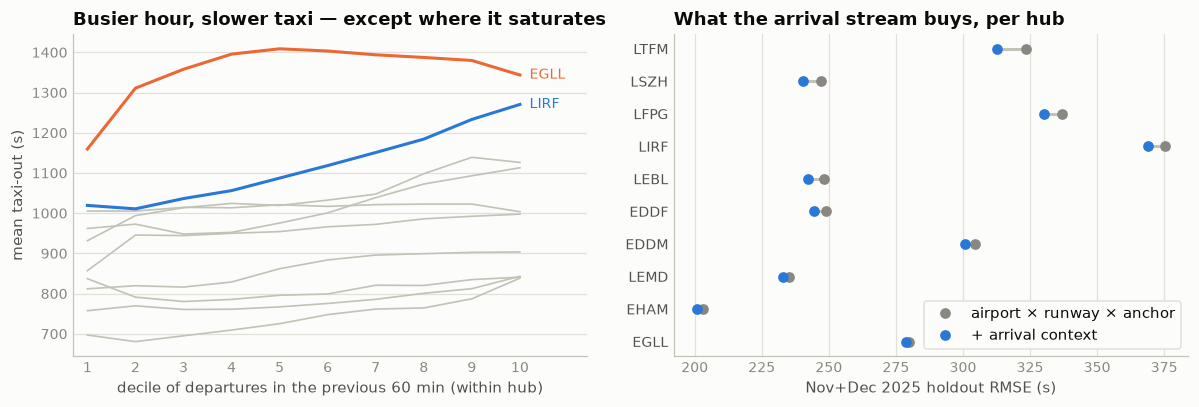

In [41]:
curve = con.sql("""
    WITH d AS (SELECT hub, taxi_out::DOUBLE y, n_dep_60 FROM dep_ctx
               WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600),
         b AS (SELECT *, ntile(10) OVER (PARTITION BY hub ORDER BY n_dep_60) q FROM d)
    SELECT hub, q, avg(y) mean_taxi FROM b GROUP BY 1, 2 ORDER BY 1, 2""").df()
gain = con.sql(f"""
    SELECT hub, sqrt(avg((v.y - coalesce(CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                         CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                         rung0.m))^2)) base,
                sqrt(avg((v.y - coalesce(CASE WHEN rung3.c >= {MIN_N} THEN rung3.m END,
                                         CASE WHEN rung2.c >= {MIN_N} THEN rung2.m END,
                                         CASE WHEN rung1.c >= {MIN_N} THEN rung1.m END,
                                         rung0.m))^2)) with_ctx
    FROM lad_b v LEFT JOIN rung3 USING (hub, rwy, q_anc, q_dep, q_tin)
    LEFT JOIN rung2 USING (hub, rwy, q_anc) LEFT JOIN rung1 USING (hub, rwy)
    LEFT JOIN rung0 USING (hub)
    WHERE v.is_val GROUP BY 1 ORDER BY base - with_ctx""").df()
print("per-hub holdout RMSE, before and after the arrival context:")
print(gain.assign(gain=(gain.base - gain.with_ctx)).round(1).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
for hub, g in curve.groupby("hub"):
    hi = hub in ("LIRF", "EGLL")
    a1.plot(g.q, g.mean_taxi, color={"LIRF": BLUE, "EGLL": ORANGE}.get(hub, BASELINE),
            lw=2.0 if hi else 1.1, zorder=3 if hi else 1)
    if hi:
        a1.text(10.2, g.mean_taxi.iloc[-1], hub, fontsize=9, va="center",
                color={"LIRF": BLUE, "EGLL": ORANGE}[hub])
a1.set_xticks(range(1, 11))
a1.set_xlim(0.7, 11.4)
a1.set_title("Busier hour, slower taxi — except where it saturates")
a1.set_xlabel("decile of departures in the previous 60 min (within hub)")
a1.set_ylabel("mean taxi-out (s)")
style(a1)

y = np.arange(len(gain))
a2.hlines(y, gain.with_ctx, gain.base, color=BASELINE, lw=2)
a2.plot(gain.base, y, "o", color=MUTED, ms=6, label="airport × runway × anchor")
a2.plot(gain.with_ctx, y, "o", color=BLUE, ms=6, label="+ arrival context")
a2.set_yticks(y, gain.hub, color=INK2)
a2.set_title("What the arrival stream buys, per hub")
a2.set_xlabel("Nov+Dec 2025 holdout RMSE (s)")
a2.legend(loc="lower right", frameon=True, facecolor=SURFACE, edgecolor=GRID, framealpha=1)
style(a2, x_grid=True, y_grid=False)
fig.tight_layout(w_pad=2.5)
plt.show()

**Findings**

- Two values, 4,857,331 rows, **zero nulls** in either file — and the only column whose value we
  know before reading the row, since every prediction is a `DEP`. As a feature it is a constant:
  worth nothing, and it will never enter the model matrix.
- **The leak map is two columns wide.** Of the 30 columns, exactly `BLOCK_TIME_UTC_mvt` and
  `TAXITIME_SEC_mvt` are blanked in `ranking.parquet`, and only on `DEP` rows — 100% null there,
  0% everywhere else. The other 28 are as populated at prediction time as in training, including
  `RUNWAY_mvt` and `STAND_mvt` at 0.00% null on both phases and the whole `_flt` block at 1.53%.
  The one other column that moves between the files at all is `FLIGHT_ID_mvt` (§2's matching
  failures, 1.08% → 1.53% on departures).
  - As a rule: **the target's other endpoint is the only thing hidden.** Taxi-out is
    takeoff − off-block; we are given the takeoff and asked for the gap. Any feature that
    reconstructs a departure's own off-block time from the movement side is a leak. Everything
    else in the file — *both phases* — is fair game.
- **Balance:** each hub launches within ±0.6% of what it receives (LEMD +0.55%, LTFM −0.34%), in
  both files. An airport conserves aircraft, so the arrival stream is a same-size mirror of the
  departure stream, not a small side dataset.
- **The phase flip is a pooling trap.** `ADEP`/`ADES` swap roles (§5, §6), and `MVT_TIME`,
  `BLOCK_TIME`, `SCHED_TIME`, `RUNWAY`, `STAND` and the target all mean something different on
  each side — takeoff vs landing, off-block vs in-block, taxi-out vs taxi-in. They are not
  comparable quantities: over the same column, 981 s mean taxi-out against 535 s taxi-in, across
  53 departure runways and 54 arrival ones. Every statistic in this notebook has had to filter on
  phase, and the pipeline trains on `PHASE_mvt = 'DEP'` for exactly that reason.
- **The arrival half is not a spectator.** 344,693 ranking arrivals, fully populated, sit on the
  same days and the same runways as the 344,841 departures we predict — and `pipeline/train.py`
  reads none of them. Two crude context variables built from cleared columns alone (departures in
  the previous 60 min by takeoff time; mean taxi-in of arrivals in the previous 60 min) move the
  out-of-sample ladder:

  | rung | Nov+Dec 2025 holdout RMSE |
  |---|---:|
  | airport | 355.2 s |
  | + runway | 341.7 s |
  | + `AOBT_3` anchor (12 bins) | 283.6 s |
  | **+ arrival context (5 × 5 bins)** | **278.4 s** |

  **−5.2 s on top of the three strongest things the model already has**, held out, from plain
  group means with a support-30 cascade and no tuning. Departures-in-the-hour carries more of it
  (−3.8 s) than mean-taxi-in (−2.1 s), and the two are not redundant. Every hub gains: LTFM
  −11.0 s, LSZH −6.8, LFPG −6.4, LIRF −6.2 at the top, EGLL −1.2 at the bottom.
- Worth recording because it corrects an easy assumption: **the `AOBT_3` anchor is not the answer
  handed over.** Taken raw, `MVT_TIME − AOBT_3` predicts taxi-out at RMSE 361.6 s — *worse than
  the airport mean* — with a +52 s median bias and only 21% of rows inside a minute. NM's
  actual-off-block for the flown trajectory and the airport's own block time are different
  clocks. It is the ladder's biggest single step (−58 s) precisely because the model can
  calibrate that offset per airport and runway; it is not a shortcut, and it is missing on 1.53%
  of the rows we must predict.
- The context survives the ranking file's shape. It is two disjoint month-blocks, so the windows
  at 00:00 on 1 Jan and 1 Jul open cold — 30 departures of 344,841, ignorable. Otherwise the
  context is indistinguishable across the files: 99.88% coverage on both, 34.7 vs 35.4
  departures/hour, 30.1 vs 30.8 arrivals/hour, and a mean prior-hour taxi-in of 546 s in each.
- **Use in modeling:** `PHASE_mvt` is a row filter, never a feature — but it is the key to the
  file's other half. Build per-hub rolling airport-state features off the *full* movement stream,
  both phases, anchored on `MVT_TIME_UTC_mvt`, and join them onto the departures. No derived
  parquet here, deliberately: unlike §2's and §4a's recovery layers, which freeze research
  decisions, this is one window query whose parameters are still open — the time-column sections
  own the choice of window and lag. Before generalizing the recipe, though, §7a: one of these two
  variables turns out not to be measuring congestion at all.

### 7a · Addendum — the arrival stream is a runway-configuration sensor

One of §7's two context variables misbehaves. Mean taxi-in over the previous hour correlates
*positively* with taxi-out at eight of the ten hubs (LFPG +0.20, EGLL +0.16, EDDF +0.13) —
slow surface, slow everywhere, as expected. At Schiphol it correlates **−0.28**: the longer
arrivals have been taxiing in, the *shorter* the departures taxi out. Either the variable is
noise at EHAM, or it is not measuring congestion.

It is not measuring congestion. It is reading the **runway configuration** off the arrival
stream — and Schiphol's geometry makes that reading invert.

In [42]:
print("EHAM taxi-in by arrival runway — the runways are not interchangeable:")
print(con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi_in
    FROM {T} WHERE PHASE_mvt = 'ARR' AND ADES_mvt = 'EHAM'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

print("\nEHAM taxi-out by departure runway — and 36L is 18R's other end:")
print(con.sql(f"""
    SELECT RUNWAY_mvt rwy, count(*) n, round(avg(TAXITIME_SEC_mvt)) mean_taxi_out
    FROM {T} WHERE PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM'
      AND TAXITIME_SEC_mvt BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY n DESC LIMIT 6""").df().to_string(index=False))

# add "share of arrivals landing on the Polderbaan" to the same rolling window
con.sql(f"""
    CREATE OR REPLACE TABLE eham_ctx AS
    SELECT *, avg(taxi_in) OVER w mean_tin_60,
              avg(CASE WHEN ph = 'ARR' THEN (rwy = '18R')::INT END) OVER w share_18R
    FROM (SELECT PHASE_mvt ph, MVT_TIME_UTC_mvt t, RUNWAY_mvt rwy, TAXITIME_SEC_mvt taxi,
                 CASE WHEN PHASE_mvt = 'ARR' THEN TAXITIME_SEC_mvt END taxi_in
          FROM {T} WHERE (PHASE_mvt = 'DEP' AND ADEP_mvt = 'EHAM')
                      OR (PHASE_mvt = 'ARR' AND ADES_mvt = 'EHAM'))
    WINDOW w AS (ORDER BY t RANGE BETWEEN INTERVAL 60 MINUTE PRECEDING AND CURRENT ROW)""")

print("\nsorting EHAM departures by the prior hour's mean taxi-in:")
print(con.sql("""
    WITH d AS (SELECT taxi::DOUBLE y, rwy, mean_tin_60, share_18R FROM eham_ctx
               WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND mean_tin_60 IS NOT NULL),
         b AS (SELECT *, ntile(10) OVER (ORDER BY mean_tin_60) q FROM d)
    SELECT q, count(*) n, round(avg(mean_tin_60)) prior_hr_taxi_in,
           round(100*avg(share_18R)) pct_arr_on_18R, mode(rwy) top_dep_rwy,
           round(avg(y)) dep_taxi_out
    FROM b GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

print("\nthe configuration split — one flow, and only one phase pays for the Polderbaan:")
print(con.sql("""
    SELECT CASE WHEN share_18R >= 0.5 THEN '18R landing (south flow)'
                ELSE 'other configuration' END config, count(*) n,
           round(avg(taxi)) mean_taxi_out,
           round(100.0*count(*) FILTER (rwy = '36L')/count(*), 1) pct_dep_36L,
           round(100.0*count(*) FILTER (rwy = '24')/count(*), 1) pct_dep_24,
           round(100.0*count(*) FILTER (rwy = '18L')/count(*), 1) pct_dep_18L
    FROM eham_ctx WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND share_18R IS NOT NULL
    GROUP BY 1 ORDER BY 1""").df().to_string(index=False))

EHAM taxi-in by arrival runway — the runways are not interchangeable:
rwy     n  mean_taxi_in
18R 92274         776.0
 06 60216         303.0
18C 37554         407.0
36R 28541         289.0
 27 10460         370.0
 22  9724         293.0

EHAM taxi-out by departure runway — and 36L is 18R's other end:
rwy     n  mean_taxi_out
 24 85212          665.0
36L 58570         1082.0
18L 55571          735.0
36C 30899          729.0
 09  7855          836.0
 22  4694          276.0



sorting EHAM departures by the prior hour's mean taxi-in:
 q     n  prior_hr_taxi_in  pct_arr_on_18R top_dep_rwy  dep_taxi_out
 1 24778             258.0             0.0         36L         915.0
 2 24778             296.0             0.0         36L         914.0
 3 24778             331.0             0.0         36L         905.0
 4 24777             385.0             1.0         36L         870.0
 5 24777             496.0            25.0          24         775.0
 6 24777             586.0            53.0          24         661.0
 7 24777             634.0            68.0          24         679.0
 8 24777             677.0            81.0          24         679.0
 9 24777             719.0            89.0          24         688.0
10 24777             816.0            92.0          24         749.0

the configuration split — one flow, and only one phase pays for the Polderbaan:
                  config      n  mean_taxi_out  pct_dep_36L  pct_dep_24  pct_dep_18L
18R landing (sou

 hub      r
EHAM -0.281
LEBL -0.077
LSZH  0.014
LEMD  0.060
LTFM  0.067
LIRF  0.098
EDDM  0.099
EDDF  0.129
EGLL  0.160
LFPG  0.197


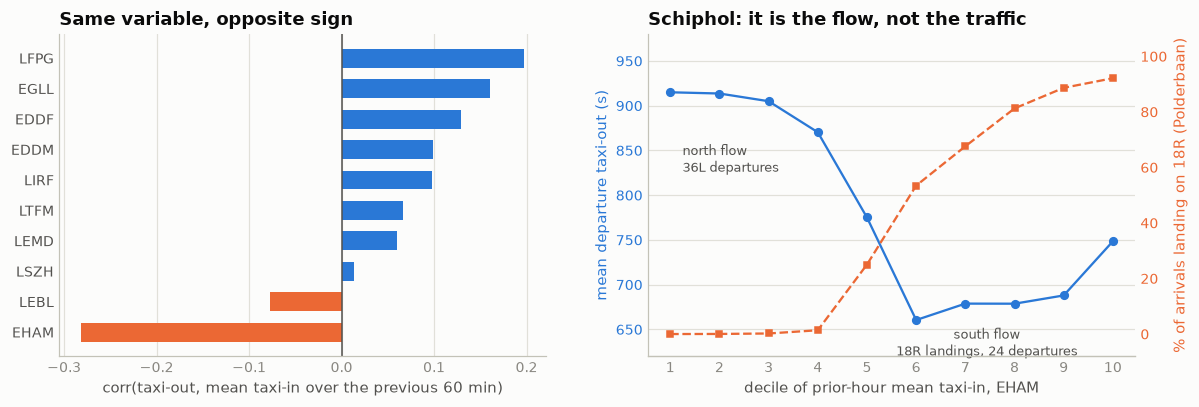

In [43]:
corr = con.sql("""
    SELECT hub, corr(taxi_out, mean_tin_60) r FROM dep_ctx
    WHERE ds = 'training' AND ph = 'DEP' AND taxi_out BETWEEN 1 AND 3600
    GROUP BY 1 ORDER BY r""").df()
mech = con.sql("""
    WITH d AS (SELECT taxi::DOUBLE y, mean_tin_60, share_18R FROM eham_ctx
               WHERE ph = 'DEP' AND taxi BETWEEN 1 AND 3600 AND mean_tin_60 IS NOT NULL),
         b AS (SELECT *, ntile(10) OVER (ORDER BY mean_tin_60) q FROM d)
    SELECT q, avg(y) taxi_out, 100*avg(share_18R) pct_18R FROM b GROUP BY 1 ORDER BY 1""").df()
print(corr.round(3).to_string(index=False))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.8))
y = np.arange(len(corr))
a1.barh(y, corr.r, height=0.62, color=[ORANGE if v < 0 else BLUE for v in corr.r])
a1.axvline(0, color=INK2, lw=1)
a1.set_yticks(y, corr.hub, color=INK2)
a1.set_title("Same variable, opposite sign")
a1.set_xlabel("corr(taxi-out, mean taxi-in over the previous 60 min)")
style(a1, x_grid=True, y_grid=False)

# the two series are named by their own coloured axis labels — no legend to sit on the data
a2.plot(mech.q, mech.taxi_out, "o-", color=BLUE, ms=5)
a2.set_ylabel("mean departure taxi-out (s)", color=BLUE)
a2.tick_params(axis="y", colors=BLUE)
a2.set_ylim(620, 980)
a2.set_xticks(range(1, 11))
a2.set_xlabel("decile of prior-hour mean taxi-in, EHAM")
a2.set_title("Schiphol: it is the flow, not the traffic")
style(a2)
a3 = a2.twinx()
a3.plot(mech.q, mech.pct_18R, "s--", color=ORANGE, ms=4.5)
a3.set_ylabel("% of arrivals landing on 18R (Polderbaan)", color=ORANGE)
a3.tick_params(axis="y", colors=ORANGE, length=0)
a3.set_ylim(-8, 108)
a3.grid(False)
a3.spines[["top", "left", "right"]].set_visible(False)
a2.annotate("north flow\n36L departures", (1, 915), textcoords="offset points", xytext=(8, -52),
            fontsize=8.5, color=INK2)
a2.annotate("south flow\n18R landings, 24 departures", (8, 679), textcoords="offset points",
            xytext=(-18, -34), fontsize=8.5, color=INK2, ha="center")
fig.tight_layout(w_pad=3.2)
plt.show()

**Addendum findings**

- **EHAM's arrival runways are not interchangeable.** Landing on **18R, the Polderbaan**, costs a
  mean **776 s** of taxi-in; landing on 06 or 36R costs 303 s and 289 s. The Polderbaan sits some
  7 km from the terminal — built for noise abatement, not convenience. So "mean taxi-in over the
  last hour" at EHAM is, to first order, a **thermometer for whether 18R is the landing runway**.
- **And 18R landing implies a configuration in which departures taxi less.** Sorting departures by
  the prior hour's mean taxi-in: in the bottom four deciles 0–1% of arrivals used 18R, the modal
  departure runway is **36L**, and taxi-out averages 870–915 s. From the sixth decile up, 53–92%
  of arrivals used 18R, the modal departure runway is **24, the Kaagbaan**, and taxi-out averages
  661–749 s. Split at 50% 18R: departures on 36L collapse from 44.0% to 0.2%, runways 24 and 18L
  take 94.2% of the traffic, and mean taxi-out falls **869 → 685 s**.
- The asymmetry is geometric, not statistical. **36L is 18R's other end** — and it is EHAM's
  longest departure taxi (1,082 s, against 665 s for 24). The Polderbaan is always the long leg;
  the flow direction only decides *which phase pays for it*. South flow lands on 18R and departs
  from the near runways; north flow departs from 36L and lands on the near ones. One rolling
  average of arrival taxi-in tells us which of the two we are in — which is why the correlation
  at EHAM is not weak-and-noisy but strong-and-backwards.
- **The sign is airport-specific and must be learned as such.** corr(taxi-out, prior-hour mean
  taxi-in) runs from +0.20 (LFPG), +0.16 (EGLL) and +0.13 (EDDF) down through +0.01 (LSZH) to
  −0.08 (LEBL) and −0.28 (EHAM). A single global "the surface is slow" feature would cancel these
  against each other; interacted with the hub, the same number carries congestion at eight
  airports and flow direction at Schiphol. It also explains §7's per-hub table, where EHAM gains
  the second least from the context — a variable pulling in two directions at once is doing half
  its job.
- **Use in modeling:** keep the rolling arrival statistics, but as per-airport quantities the
  model may interact with `ADEP_mvt` — never globally standardized, which would destroy exactly
  the structure above. LightGBM gets the interaction for free from a categorical airport split.
  Better still, give it the configuration directly: **the mix of arrival runways in the previous
  hour is observable at prediction time** (§7's leak map: `RUNWAY_mvt` is 0.00% null on both
  phases of `ranking.parquet`) and names the flow explicitly, where mean taxi-in only proxies it.
  `RUNWAY_mvt`'s own section takes that up — the natural home, since the departure runway is
  likewise known for every row we predict.